# LOGISMART — Evidencias de modelado y evaluación (H4–H5)

Este notebook **documenta e interpreta los resultados** producidos por los módulos de `src/`; no entrena modelos ni recalcula SHAP. Su objetivo es servir como evidencia académica del proceso CRISP-DM.

**Fuente de los resultados:** `output/resultados/<categoria>/*.json` y `output/graficos/*.png`, generados por los comandos `python main.py --proceso entrenar`, `evaluar`, `explicar`, `optimizar`, `sesgos` y `evaluacion-final`.

**Alcance:** todos los registros son sintéticos. Las métricas y explicaciones describen el comportamiento del modelo en la simulación, no su rendimiento operativo real. Las cifras comentadas corresponden a la ejecución completa documentada; si se regenera el dataset, se cambia el modelo o se modifica la semilla, deberán actualizarse las interpretaciones.


In [49]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
ruta = BASE / "output" / "resultados" / "modelado" / "resultados_modelado.json"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso entrenar")
resultados = json.loads(ruta.read_text(encoding="utf-8"))
print("Modelo elegido:", resultados["modelo_elegido"])
print("Modo rápido:", resultados["modo_rapido"])
print("Períodos:", resultados["periodos"])
print("Filas usadas:", resultados["filas_utilizadas"])

Modelo elegido: XGBoost
Modo rápido: False
Períodos: {'train': '2025-08 a 2026-06', 'validacion': '2026-07', 'test': '2026-08 a 2026-09'}
Filas usadas: {'train': 825299, 'validacion': 74766, 'test': 149935}


## Comparación de modelos en validación

Se utilizó una **división temporal**: entrenamiento (agosto de 2025 a junio de 2026), validación (julio de 2026) y prueba final (agosto–septiembre de 2026). Las transformaciones que aprenden de los datos, incluida la imputación, se ajustan solamente con entrenamiento.

Se compararon **Random Forest** y **XGBoost** sobre julio de 2026. XGBoost obtuvo ROC-AUC **0.7037** y PR-AUC **0.2898**, frente a **0.6984** y **0.2848** de Random Forest, respectivamente. Por ello, se seleccionó XGBoost según el criterio implementado (ROC-AUC y PR-AUC como desempate).

Las métricas de clasificación de esta tabla usan un umbral fijo de **0.5**, solo como referencia. Con ese umbral, XGBoost recupera aproximadamente **0.98 %** de los retrasos de validación; por tanto, se requiere analizar un umbral alternativo para fines preventivos. **El conjunto de test no intervino en la selección del modelo ni del umbral.**


In [50]:
tabla = pd.DataFrame(resultados["resultados_validacion_umbral_0_5"]).T
display(tabla.drop(columns=["matriz_confusion"]).round(4))

,roc_auc,pr_auc,precision,recall,f1,tasa_retraso_real,tasa_alertas,umbral
Random Forest,0.698365,0.28482,1.0,0.000097,0.000194,0.13767,0.000013,0.5
XGBoost,0.703692,0.289849,0.647436,0.009812,0.019332,0.13767,0.002087,0.5


## Evaluación final en test

El modelo seleccionado se evaluó con los datos de **agosto y septiembre de 2026**, manteniendo el umbral definido en validación (**0.15**).

**Resultados obtenidos:** ROC-AUC **0.7074**; PR-AUC **0.3044**; precisión **34.56 %**; recall **30.95 %**; F1 **0.3265**. El modelo genera alertas para el **13.02 %** de las operaciones de prueba.

Según la matriz de confusión, de **21.795** retrasos reales se detectaron **6.746** y quedaron sin alerta **15.049**; además hubo **12.776** falsas alarmas. Esto evidencia una capacidad de discriminación útil para priorización, pero una sensibilidad limitada si la meta es advertir la mayoría de los retrasos.

La tasa de retraso observada en test fue **14.54 %**, mientras que la precisión de las alertas fue **34.56 %**, aproximadamente **2.38 veces** la tasa base. Esta concentración no demuestra que emitir una alerta evite un retraso.


In [51]:
r = resultados["resultado_test"]
display(pd.Series({k: v for k, v in r.items() if k != "matriz_confusion"}, name="Test").to_frame())
print("Matriz de confusión [TN, FP; FN, TP]:")
print(pd.DataFrame(r["matriz_confusion"], index=["Real 0", "Real 1"], columns=["Pred 0", "Pred 1"]))

,Test
roc_auc,0.707352
pr_auc,0.304437
precision,0.345559
recall,0.309521
f1,0.326548
tasa_retraso_real,0.145363
tasa_alertas,0.130203
umbral,0.150000


Matriz de confusión [TN, FP; FN, TP]:
        Pred 0  Pred 1
Real 0  115364   12776
Real 1   15049    6746


## Auditoría de umbrales y comunas

Genera los resultados con `python main.py --proceso evaluar`. Los gráficos de este notebook **no cambian parámetros ni reentrenan**.

In [52]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent

resultados_dir = base / "output" / "resultados" / "modelado"
graficos_dir = base / "output" / "graficos"
def leer(nombre):
    ruta = resultados_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta python -m src.evaluacion desde la raíz.")
    return json.loads(ruta.read_text(encoding="utf-8"))

resumen = leer("resultados_modelado.json")
umbrales = pd.DataFrame(leer("auditoria_umbrales_validacion.json"))
ruta_comunas = base / "output" / "resultados" / "sesgos_equidad" / "auditoria_comunas_test.json"
if not ruta_comunas.exists():
    raise FileNotFoundError(f"Falta {ruta_comunas}. Ejecuta primero: python main.py --proceso evaluar")
comunas = pd.read_json(ruta_comunas)
assert resumen["modo_rapido"] is False, "Ejecuta entrenamiento completo antes de documentar resultados oficiales"
print("Modelo:", resumen["modelo_elegido"], "| umbral oficial:", round(resumen["umbral_elegido_en_validacion"], 3))

Modelo: XGBoost | umbral oficial: 0.15


## 1. Umbrales de clasificación — validación

El umbral oficial **0.15** se eligió maximizando el **F1-score en validación**, dentro del rango de candidatos definido en `src/modelado.py`.

El contraste permite visualizar el compromiso entre detectar retrasos y generar alertas:

| Umbral | Precision | Recall | Operaciones con alerta |
|---|---:|---:|---:|
| 0.10 | 21.5 % | 71.2 % | 45.6 % |
| **0.15 (oficial)** | **26.2 %** | **52.3 %** | **27.5 %** |
| 0.20 | 31.1 % | 34.4 % | 15.3 % |

Un umbral menor identifica más retrasos, pero aumenta la carga de revisión y las falsas alarmas. El criterio F1 es adecuado como **línea base técnica**; no demuestra que 0.15 sea óptimo para el negocio. Eso requeriría conocer los costos de no detectar un atraso y la capacidad real de intervención logística.

**Nota metodológica:** estos porcentajes son de **validación (julio)**, no del test final. Las tasas pueden cambiar entre períodos por diferencias en la distribución de operaciones.


,umbral,precision,recall,f1,tasa_alertas,tp,fp,fn,tn
0,0.05,0.1567,0.9424,0.2687,0.8279,9700,52196,593,12277
1,0.10,0.2152,0.7124,0.3306,0.4557,7333,26737,2960,37736
2,0.15,0.2616,0.5232,0.3488,0.2753,5385,15196,4908,49277
3,0.20,0.3107,0.3444,0.3267,0.1526,3545,7864,6748,56609
4,0.25,0.3624,0.2146,0.2696,0.0815,2209,3886,8084,60587
5,0.30,0.4131,0.1285,0.1961,0.0428,1323,1880,8970,62593
6,0.35,0.4791,0.0769,0.1326,0.0221,792,861,9501,63612
7,0.40,0.5306,0.0404,0.0751,0.0105,416,368,9877,64105
8,0.45,0.5734,0.0197,0.0381,0.0047,203,151,10090,64322
9,0.50,0.6474,0.0098,0.0193,0.0021,101,55,10192,64418


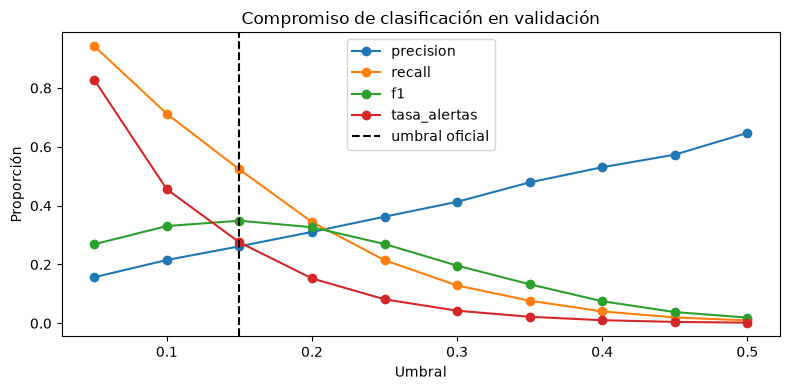

In [53]:
display(umbrales.round(4))
fig, ax = plt.subplots(figsize=(8,4))
for columna in ["precision", "recall", "f1", "tasa_alertas"]:
    ax.plot(umbrales["umbral"], umbrales[columna], marker="o", label=columna)
ax.axvline(resumen["umbral_elegido_en_validacion"], linestyle="--", color="black", label="umbral oficial")
ax.set(xlabel="Umbral", ylabel="Proporción", title="Compromiso de clasificación en validación")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Desempeño territorial — test

La evaluación por comuna revela **heterogeneidad de recall**. Entre las diez comunas con más operaciones, Santiago alcanza **42.0 %**, Las Condes **37.8 %**, Ñuñoa **21.1 %** y Quilicura **16.5 %**. La brecha Santiago–Quilicura es de **25.5 puntos porcentuales**.

Las diferencias indican que el modelo no identifica retrasos con igual sensibilidad en todos los destinos. **No constituyen por sí solas prueba de discriminación injustificada:** pueden intervenir tasas base distintas, composición de rutas, volumen de operaciones y otros factores.

Las comunas con pocos retrasos tienen estimaciones menos estables. Por eso se incorpora `muestra_suficiente_recall` como indicador descriptivo y se evita reajustar el umbral o los hiperparámetros usando resultados del test.


,comuna_destino,operaciones,retrasos,tasa_retrasos,tasa_alertas,precision,recall,muestra_suficiente_recall
0,Santiago,22358,4173,0.1866,0.2159,0.3632,0.4201,True
1,Las Condes,15973,2679,0.1677,0.1815,0.3498,0.3785,True
2,Maipú,14270,2005,0.1405,0.1093,0.3314,0.2579,True
3,Providencia,12868,1981,0.1539,0.1467,0.3506,0.3342,True
4,La Florida,12700,1736,0.1367,0.1111,0.3381,0.2748,True
5,Puente Alto,11299,1706,0.1510,0.1514,0.3413,0.3423,True
6,Ñuñoa,11088,1339,0.1208,0.0767,0.3325,0.2114,True
7,Valparaíso,7924,1208,0.1524,0.1417,0.3411,0.3171,True
8,Quilicura,7911,901,0.1139,0.0630,0.2992,0.1654,True
9,Viña del Mar,7908,1128,0.1426,0.1155,0.3582,0.2899,True


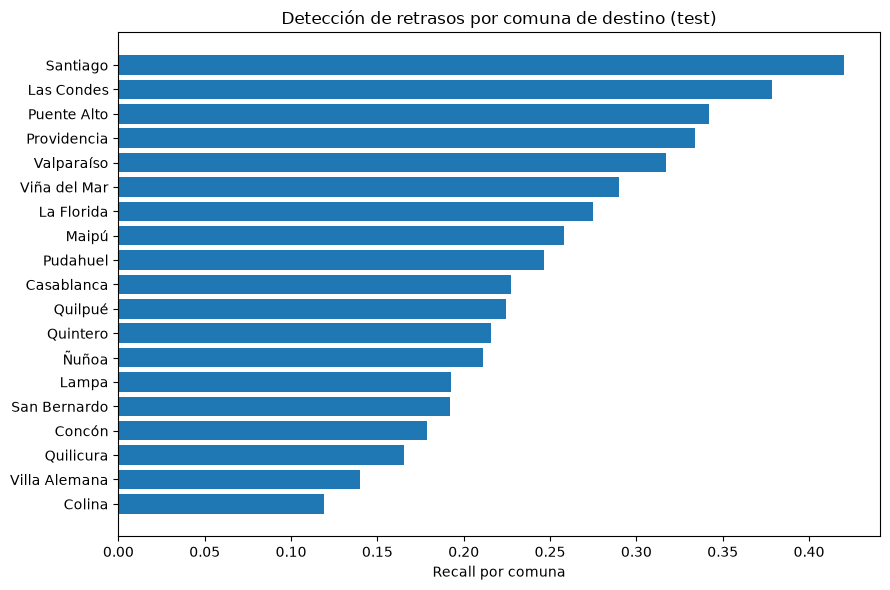

In [54]:
columnas = ["comuna_destino", "operaciones", "retrasos", "tasa_retrasos", "tasa_alertas", "precision", "recall", "muestra_suficiente_recall"]
display(comunas[columnas].round(4))
orden = comunas.sort_values("recall")
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(orden["comuna_destino"], orden["recall"])
ax.set(xlabel="Recall por comuna", title="Detección de retrasos por comuna de destino (test)")
plt.tight_layout()
plt.show()

## 3. Síntesis de evaluación y limitaciones

1. **Selección reproducible:** se compararon dos algoritmos y se eligió XGBoost por desempeño de validación, sin consultar test.
2. **Compromiso operativo:** el umbral oficial 0.15 maximiza F1 en validación; bajar el umbral mejora recall a costa de más alertas.
3. **Errores de clasificación:** el test registra 15.049 retrasos no detectados y 12.776 falsas alarmas; ambos tipos de error deben considerarse en decisiones logísticas.
4. **Variación territorial:** existen diferencias de recall entre comunas, que merecen seguimiento y análisis contextual.
5. **Naturaleza sintética:** las distribuciones y relaciones fueron diseñadas en la simulación; la evaluación no sustituye una validación con datos reales.
6. **Separación temporal:** las métricas de test se registran como evaluación final; no deben emplearse para decidir nuevas variables, umbrales o hiperparámetros sin una nueva evaluación independiente.

**Relación con el objetivo de negocio:** una predicción de retraso no equivale a una reducción del retraso. Para demostrar una disminución del 20 % sería necesario definir intervenciones, costos y una evaluación del efecto de aplicarlas.


## 4. Explicabilidad global SHAP — evidencia H4-T2

Los valores SHAP se calcularon sobre una muestra reproducible de **500 operaciones de validación (julio de 2026)** y se agruparon por predictor original: las columnas de codificación one-hot y los indicadores de datos faltantes se suman por observación antes de calcular la importancia global.

La importancia global se presenta mediante la **media del valor absoluto SHAP** en el margen bruto del XGBoost (**log-odds**). Este valor indica cuánto influye una variable en la salida del modelo, **sin indicar por sí solo la dirección del efecto ni una variación en puntos porcentuales de probabilidad**.

Las mayores importancias obtenidas fueron:
- `es_hora_punta`: **0.4754**.
- `mes`: **0.3586**.
- `duracion_estimada_min`: **0.2315**.
- `comuna_destino`: **0.1710**.
- `experiencia_conductor_anios`: **0.1407**.

Esto muestra un predominio de variables temporales, de planificación y contexto territorial en las predicciones del modelo. No demuestra relaciones causales.

**Precaución sobre `mes`:** toda la muestra SHAP procede de **julio**, por lo que `mes = 7` en todas las observaciones. Su importancia y contribución reflejan cómo el modelo utiliza ese valor dentro de su representación aprendida; **esta visualización no permite concluir que el riesgo crezca progresivamente a medida que avanzan los meses**. Para estudiar variaciones entre meses se requeriría un análisis específico con registros de varios períodos, separado de la selección y evaluación final.


Muestra: 500 | Período: validacion (julio 2026)
Escala: log-odds / margen bruto de XGBoost; NO puntos porcentuales de probabilidad


,variable,valor
0,es_hora_punta,0.4754
1,mes,0.3586
2,duracion_estimada_min,0.2315
3,comuna_destino,0.1710
4,experiencia_conductor_anios,0.1407
5,distancia_km,0.1195
6,tipo_vehiculo,0.0979
7,dia_semana,0.0791
8,franja_horaria,0.0499
9,n_paquetes,0.0396


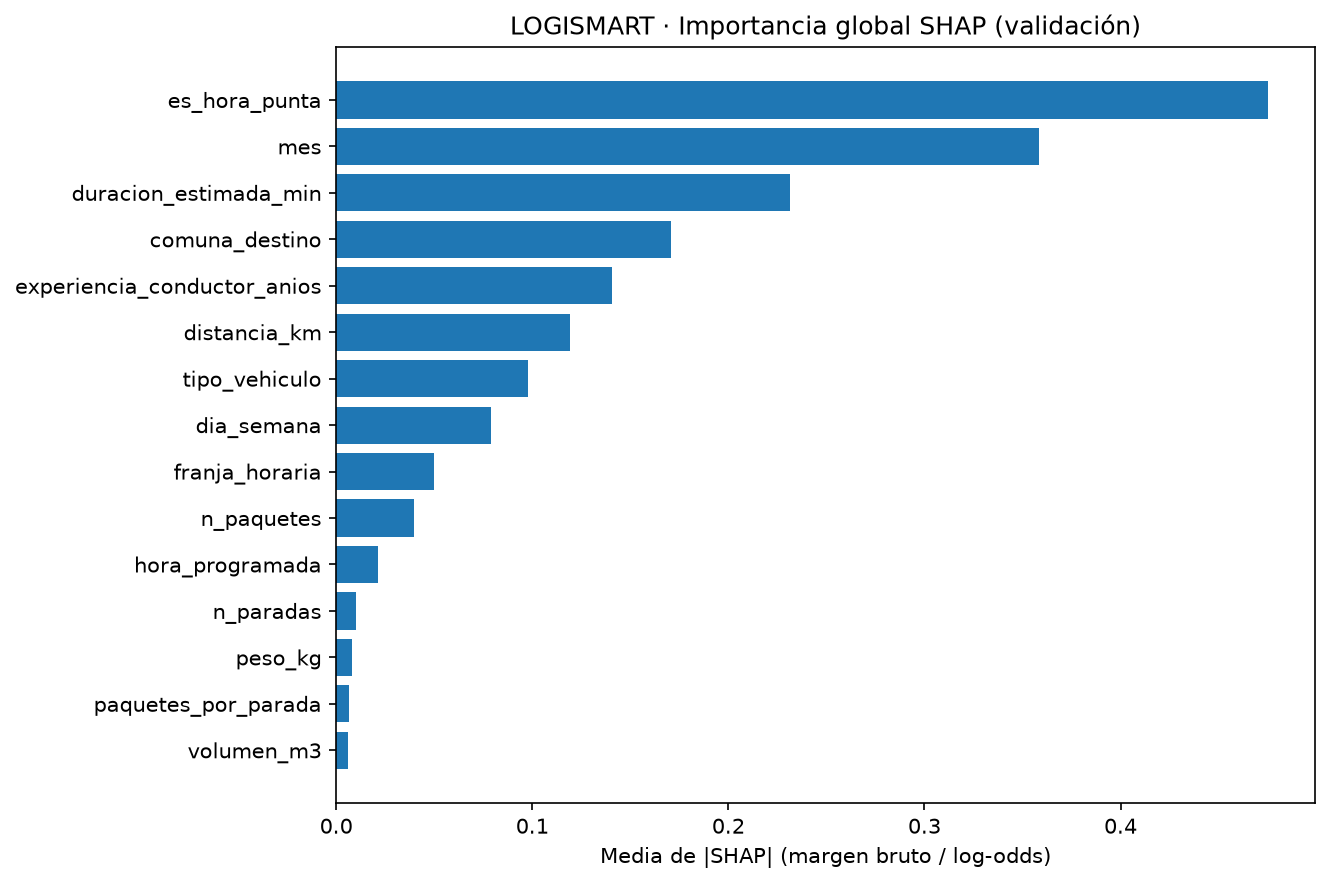

In [55]:
from IPython.display import Image, display
ruta_shap = base / "output" / "resultados" / "explicabilidad" / "explicabilidad_shap.json"
ruta_fig = graficos_dir / "importancia_shap.png"
if not ruta_shap.exists() or not ruta_fig.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso explicar")
explicacion = json.loads(ruta_shap.read_text(encoding="utf-8"))
print("Muestra:", explicacion["numero_operaciones"], "| Período:", explicacion["conjunto_explicado"])
print("Escala:", explicacion["escala_shap"])
display(pd.DataFrame(explicacion["importancia_global_media_abs_shap"]).head(15).round(4))
display(Image(filename=str(ruta_fig)))

### Explicación local y lectura crítica

Una contribución SHAP positiva desplaza el **margen bruto** de XGBoost hacia un mayor riesgo y una negativa lo desplaza hacia un menor riesgo. Los valores están expresados en **log-odds**, no en porcentajes de probabilidad ni en efectos causales.

En la ejecución documentada, el ejemplo local elegido corresponde a la operación con **mayor probabilidad estimada dentro de la muestra de 500 registros**. Esa elección sirve para ilustrar cómo funciona el modelo, pero **no representa una operación promedio** ni una prueba de que sus características causen retrasos.


In [56]:
ejemplo = explicacion["ejemplo_local"]
print("Probabilidad predicha:", round(ejemplo["probabilidad_predicha"], 4))
display(pd.DataFrame(ejemplo["top_atribuciones_por_variable"]).head(12).round(4))

Probabilidad predicha: 0.6035


,variable,shap
0,duracion_estimada_min,0.6921
1,es_hora_punta,0.5780
2,distancia_km,0.3373
3,mes,0.3328
4,comuna_destino,0.2888
5,dia_semana,0.2618
6,experiencia_conductor_anios,0.2455
7,tipo_vehiculo,-0.0907
8,n_paquetes,0.0430
9,franja_horaria,0.0313


### Interpretación de la importancia SHAP global

`es_hora_punta` tiene la mayor influencia media; le siguen `mes` y `duracion_estimada_min`. También destacan `comuna_destino`, `experiencia_conductor_anios`, `distancia_km` y `tipo_vehiculo`. En cambio, `peso_kg`, `volumen_m3` y `paquetes_por_parada` presentan aportes mucho menores en esta ejecución.

Varias características están relacionadas entre sí: `es_hora_punta` se deriva de `hora_programada`, y la duración estimada se relaciona con distancia y número de paradas. Por tanto, la atribución de importancia puede concentrarse en algunas variables correlacionadas o derivadas. **No corresponde eliminar predictores únicamente por su menor importancia SHAP**.

El mes es particularmente sensible a la construcción del dataset sintético: el generador incorpora una evolución temporal del riesgo. Estas explicaciones deben interpretarse como un análisis del **comportamiento del modelo entrenado**, no como descubrimientos causales sobre transporte real.


## 5. SHAP beeswarm y waterfall — evidencia H4-T2

Los gráficos se generan en `src/explicabilidad.py` y se guardan en `output/graficos/`. El notebook únicamente los visualiza.

**Beeswarm:** cada punto es una operación de validación. El eje horizontal expresa la contribución SHAP al margen bruto del modelo. A la **derecha de cero** la variable aumenta el riesgo predicho y a la **izquierda** lo reduce. En variables numéricas, rojo representa valores relativamente altos y azul valores bajos; las variables categóricas se muestran en gris porque no existe una escala cuantitativa natural de color.

**Waterfall:** descompone la predicción de una operación individual. Parte del valor base **E[f(X)]**, suma las contribuciones positivas y negativas de las variables y llega a **f(x)**. Ambos extremos están en log-odds; para expresarlos como probabilidad hay que aplicar la función sigmoide.

**Interpretación de `mes`:** como las 500 operaciones proceden de julio, todos los puntos tienen el mismo mes. La dispersión de contribuciones SHAP para `mes` **no demuestra diferencias entre meses**, ni que un mes posterior aumente necesariamente los retrasos.


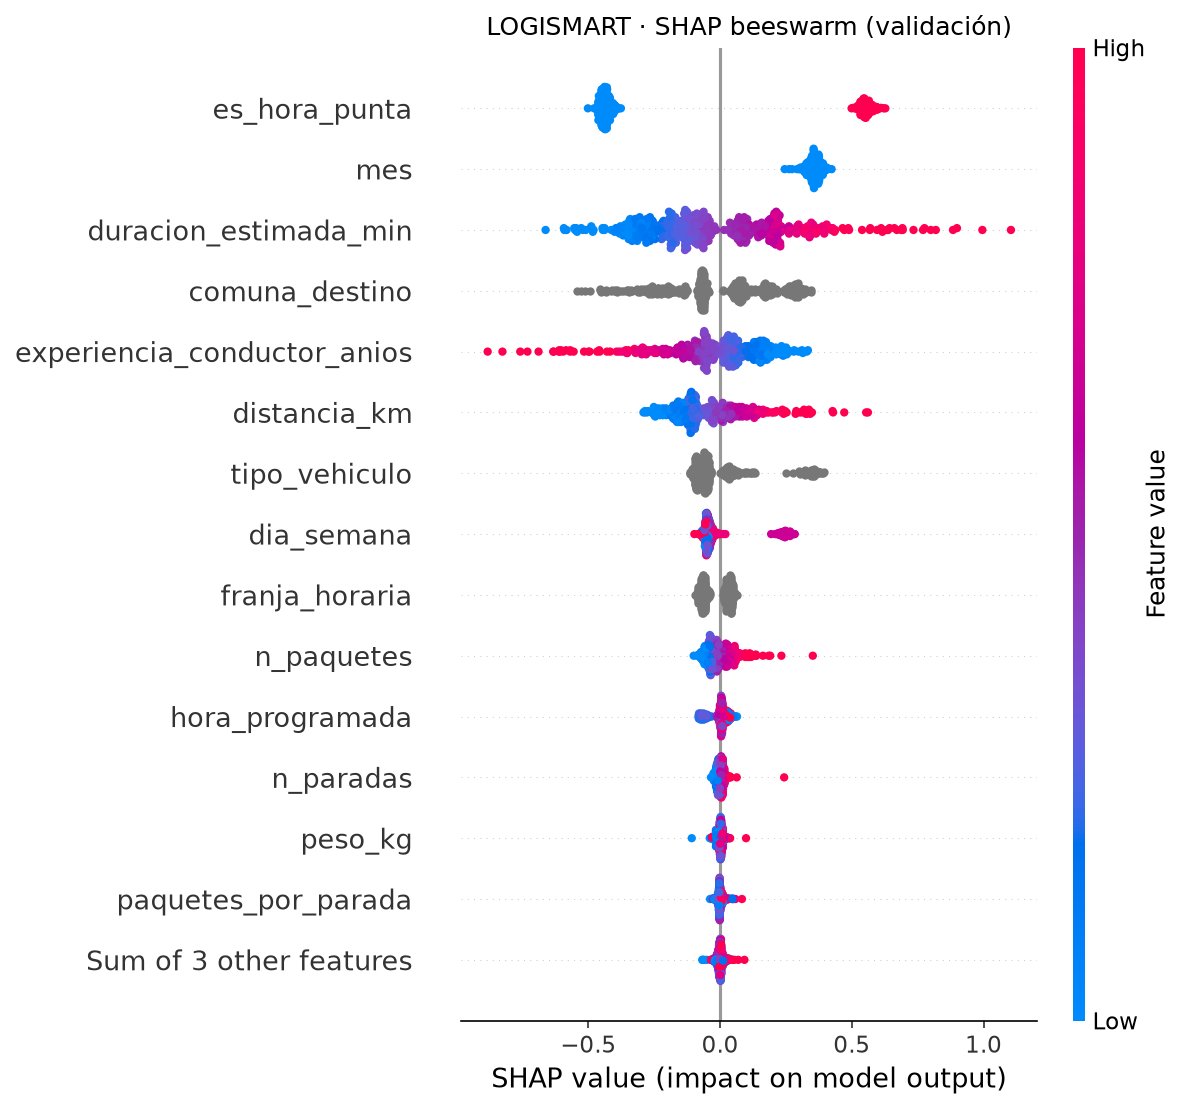

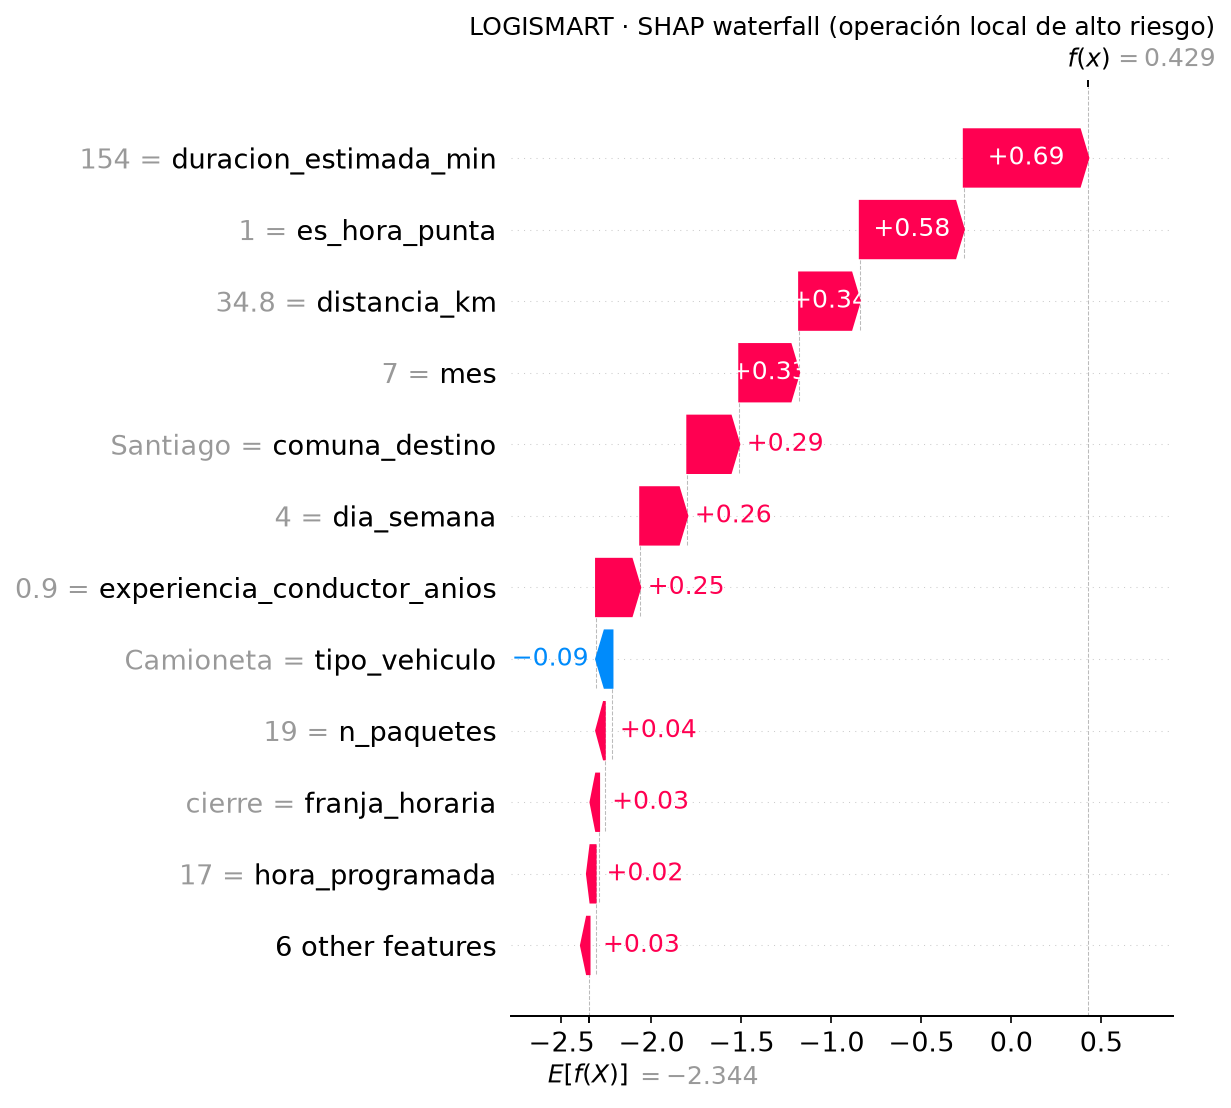

In [57]:
from IPython.display import Image, display

for nombre in ["beeswarm_shap.png", "waterfall_shap.png"]:
    ruta = graficos_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"No existe {ruta}. Ejecuta python main.py --proceso explicar")
    display(Image(filename=str(ruta)))

### Interpretación del beeswarm

En la ejecución documentada se observan los siguientes patrones:
- **Hora punta:** `es_hora_punta = 1` aparece principalmente con contribuciones positivas; `0`, con negativas. El modelo asocia la condición de hora punta con una mayor predicción de riesgo.
- **Duración estimada y distancia:** los valores altos tienden a desplazarse hacia SHAP positivo y los bajos hacia SHAP negativo.
- **Experiencia del conductor:** una experiencia mayor tiende a mostrar contribuciones negativas; en la muestra, menor experiencia se asocia con un riesgo predicho mayor.
- **Comuna y tipo de vehículo:** sus puntos grises permiten apreciar diferencias en contribuciones, pero el color no indica un orden de categorías.
- **Mes:** toda la muestra pertenece a julio. Que SHAP sea positivo para `mes = 7` no prueba una tendencia creciente entre meses.

La interpretación describe asociaciones **aprendidas por XGBoost** dentro de un dataset simulado; no establece que intervenir sobre una variable produzca automáticamente el cambio predicho.

### Interpretación del waterfall: operación de alto riesgo

El ejemplo mostrado corresponde a una operación con **154 minutos** de duración estimada, **34.8 km** de recorrido, despacho programado a las **17:00**, destino **Santiago**, **19 paquetes** y **0.9 años** de experiencia del conductor.

El modelo parte de un margen base aproximado de **−2.344** y termina en **f(x) = 0.429**. Aplicando la sigmoide, este último valor equivale aproximadamente a **60.6 % de probabilidad predicha de retraso**: supera el umbral oficial de **15 %** y, por tanto, se clasifica como operación de riesgo.

Las mayores contribuciones positivas son **duración estimada (+0.69)**, **hora punta (+0.58)**, **distancia (+0.34)**, **mes (+0.33)** y **comuna destino (+0.29)**. La categoría **Camioneta** muestra una contribución negativa pequeña (aproximadamente **−0.09**). Estas contribuciones son cambios en el margen **log-odds**, no en puntos porcentuales.

**Límites de la interpretación local:** es un ejemplo intencionalmente seleccionado por alta probabilidad dentro de la muestra, no un caso representativo de todas las entregas. La descomposición explica cómo el modelo produjo su estimación y no constituye evidencia de que una modificación operativa específica evite el retraso.

### Cierre de H4-T2

El análisis reúne tres niveles complementarios: **importancia global** (magnitud media), **beeswarm** (dirección y dispersión) y **waterfall** (explicación individual). En conjunto, aporta trazabilidad a las decisiones del modelo, manteniendo las limitaciones propias de datos sintéticos y de la atribución predictiva.


## 6. H4-T3 — Optimización de hiperparámetros

La búsqueda de configuraciones de **Random Forest y XGBoost** se implementa en `src/optimizacion.py` y se ejecuta con `python main.py --proceso optimizar`. El notebook **no realiza la búsqueda**: presenta sus resultados guardados.

**Diseño metodológico:** se utiliza `RandomizedSearchCV` con dos folds cronológicos expansivos **dentro del entrenamiento**, seleccionando hiperparámetros por PR-AUC. Se compara cada configuración inicial con la optimizada utilizando el **mismo subconjunto de entrenamiento**. Julio de 2026 permite una comparación externa; agosto–septiembre (test) **no interviene** en esta actividad.

**Eficiencia:** se registra tiempo de búsqueda, tiempo de ajuste y pico de asignaciones de memoria Python (`tracemalloc`, que no mide toda la RAM del proceso ni la memoria nativa de XGBoost).

**Importante:** la configuración optimizada es **candidata**; el modelo oficial serializado no se sustituye automáticamente. Una mejora en un subconjunto o en CV no garantiza mejor rendimiento futuro.

In [58]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
ruta_opt = base / "output" / "resultados" / "modelado" / "optimizacion_hiperparametros.json"
if not ruta_opt.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso optimizar")
opt = json.loads(ruta_opt.read_text(encoding="utf-8"))
print("Estrategia:", opt["estrategia"])
print("Métrica de búsqueda:", opt["metrica_busqueda"])
print("Muestra train:", opt["registros_train_usados"], "de", opt["registros_train_disponibles"])

filas = []
for modelo, info in opt["resultados"].items():
    for version, met in info["validacion_julio"].items():
        e = info["eficiencia"]
        prefijo = "base" if version == "base" else "optimizado"
        filas.append({
            "Modelo": modelo,
            "Versión": version,
            "PR-AUC julio": met["pr_auc"],
            "ROC-AUC julio": met["roc_auc"],
            "Segundos ajuste": e[f"{prefijo}_segundos_fit"],
            "Memoria Python pico (MB)": e[f"{prefijo}_pico_memoria_python_mb"],
            "PR-AUC mejor CV": info["pr_auc_cv_mejor"] if version == "optimizado" else None,
        })
display(pd.DataFrame(filas).round(4))
for modelo, info in opt["resultados"].items():
    print(f"\n{modelo} — mejor configuración:\n{info['hiperparametros_elegidos']}")
    print("Tiempo total de búsqueda:", round(info["eficiencia"]["busqueda_segundos"], 1), "segundos")
    display(pd.DataFrame(info["configuraciones_cv"]).drop(columns=["parametros"]).round(4))

Estrategia: RandomizedSearchCV con dos folds mensuales expansivos dentro de train
Métrica de búsqueda: PR-AUC (average_precision) de folds en train
Muestra train: 100000 de 825299


,Modelo,Versión,PR-AUC julio,ROC-AUC julio,Segundos ajuste,Memoria Python pico (MB),PR-AUC mejor CV
0,Random Forest,base,0.2803,0.6939,7.4019,97.4186,NaN
1,Random Forest,optimizado,0.2773,0.6927,4.8578,96.5494,0.2330
2,XGBoost,base,0.2815,0.6996,5.1902,96.5502,NaN
3,XGBoost,optimizado,0.2881,0.7018,4.5691,96.5499,0.2383



Random Forest — mejor configuración:
{'modelo__n_estimators': 80, 'modelo__min_samples_leaf': 4, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 8}
Tiempo total de búsqueda: 21.1 segundos


,pr_auc_cv_media,pr_auc_cv_desv,segundos_fit_cv_medio,ranking
0,0.2330,0.0210,1.5229,1
1,0.2318,0.0223,2.1017,2
2,0.2318,0.0231,4.7266,3
3,0.2300,0.0228,1.9120,4



XGBoost — mejor configuración:
{'modelo__subsample': 0.7, 'modelo__n_estimators': 160, 'modelo__min_child_weight': 1, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.06, 'modelo__colsample_bytree': 0.85}
Tiempo total de búsqueda: 12.5 segundos


,pr_auc_cv_media,pr_auc_cv_desv,segundos_fit_cv_medio,ranking
0,0.2383,0.0225,1.4838,1
1,0.2346,0.0239,1.9022,2
2,0.2329,0.0229,1.2385,3
3,0.2310,0.0199,1.4864,4


### Interpretación de resultados — H4-T3 (ejecución principal)

Se ejecutó `RandomizedSearchCV` con **4 configuraciones por algoritmo** y **2 folds temporales expansivos** (hasta abril → mayo y hasta mayo → junio de 2026). La búsqueda utilizó **100.000 de las 825.299 operaciones de entrenamiento disponibles** y optimizó **PR-AUC (average precision)**. El conjunto de **julio de 2026 (74.766 operaciones)** se usó para comparar las configuraciones base y candidatas; el conjunto de prueba de agosto y septiembre **no se consultó para esta tarea**.

**Comparación en validación externa (julio):**

| Modelo | PR-AUC base | PR-AUC optimizado | ROC-AUC base → optimizado | Tiempo de ajuste base → optimizado |
|---|---:|---:|---:|---:|
| Random Forest | 0.2803 | 0.2773 | 0.6939 → 0.6927 | 7.40 s → 4.86 s |
| XGBoost | 0.2815 | **0.2881** | 0.6996 → **0.7018** | 5.19 s → **4.57 s** |

En Random Forest la optimización disminuyó ligeramente el PR-AUC (−0.0029 puntos absolutos), aunque redujo el tiempo de ajuste. Para XGBoost, PR-AUC aumentó **0.0065 puntos absolutos** (aproximadamente **2.31 % relativo**) y el tiempo de ajuste disminuyó aproximadamente **12 %**. Estos tiempos describen el ajuste de cada modelo, **sin incluir la búsqueda**: la búsqueda empleó **21.08 s en Random Forest** y **12.51 s en XGBoost**.

**Mejores hiperparámetros por PR-AUC promedio en CV:**

- **Random Forest:** `n_estimators=80`, `max_depth=8`, `min_samples_leaf=4`, `max_features='sqrt'` (**PR-AUC CV: 0.2330**).
- **XGBoost:** `n_estimators=160`, `max_depth=3`, `learning_rate=0.06`, `subsample=0.7`, `colsample_bytree=0.85`, `min_child_weight=1` (**PR-AUC CV: 0.2383**).

**Decisión:** XGBoost optimizado es el **mejor candidato dentro de este experimento de 100.000 registros**, con mejor equilibrio entre PR-AUC en julio y tiempo de ajuste. **Se conserva el XGBoost oficial** entrenado con 825.299 registros (`models/modelo_logismart.joblib`): su PR-AUC previo de validación fue 0.2898, levemente superior a 0.2881, pero las ejecuciones no son directamente comparables por el tamaño de entrenamiento. No corresponde sustituir el modelo oficial sin una comparación controlada con la configuración optimizada sobre el mismo volumen y protocolo.

**Limitaciones y cautelas:** la búsqueda exploró solamente cuatro combinaciones por modelo; por tanto, no garantiza encontrar el óptimo global. El pico de memoria informado por `tracemalloc` (~96–97 MB) refleja asignaciones Python y **no es una medición de RAM total** (no incorpora necesariamente memoria nativa de XGBoost). Las métricas se obtuvieron sobre **datos sintéticos**: no prueban mejoras operacionales reales. La selección de hiperparámetros se basó en CV interna; julio se usó para comparación externa, no para elegir una configuración en cada búsqueda. La predicción en test queda reservada al protocolo final.

**Evidencias:** `src/optimizacion.py`, `output/resultados/modelado/optimizacion_hiperparametros.json` y `output/resultados/modelado/comparacion_optimizacion.csv`. El notebook únicamente **lee y explica** esos resultados; no duplica el procedimiento de entrenamiento ni búsqueda.

## 7. H4-T4 — Análisis preliminar de diferencias territoriales

Este diagnóstico descriptivo se genera con `python main.py --proceso sesgos`, a partir de la auditoría existente (`output/resultados/sesgos_equidad/auditoria_comunas_test.json`). **No entrena ni recalcula predicciones** y no selecciona umbrales sobre test.

Se comparan por comuna: volumen de operaciones, tasa de retrasos, tasa de alertas, precision, recall y FPR; se añaden intervalos Wilson aproximados al 95 % para recall, usando como denominador el número de retrasos, no todas las operaciones.

**Limitación:** diferencias entre comunas son señales que ameritan investigación, no pruebas concluyentes de sesgo injusto. Menor representación no implica automáticamente peor desempeño; además, las tasas base y complejidad operativa pueden variar. Los intervalos asumen independencia aproximada. No se propone sancionar conductores ni modificar umbrales por resultados de test.

**Mitigación propuesta:** obtener más datos representativos por comuna, revisar calidad/cobertura y covariables, y evaluar cualquier rebalanceo exclusivamente con train y validación temporal. La auditoría exhaustiva corresponde a H5-T3.


,comuna_destino,operaciones,retrasos,recall,recall_ic95_inf,recall_ic95_sup,precision,fpr,muestra_baja_relativa
0,Santiago,22358,4173,0.420,0.405,0.435,0.363,0.169,False
1,Las Condes,15973,2679,0.378,0.360,0.397,0.350,0.142,False
2,Maipú,14270,2005,0.258,0.239,0.277,0.331,0.085,False
3,Providencia,12868,1981,0.334,0.314,0.355,0.351,0.113,False
4,La Florida,12700,1736,0.275,0.254,0.296,0.338,0.085,False
5,Puente Alto,11299,1706,0.342,0.320,0.365,0.341,0.117,False
6,Ñuñoa,11088,1339,0.211,0.190,0.234,0.333,0.058,False
7,Valparaíso,7924,1208,0.317,0.291,0.344,0.341,0.110,False
8,Quilicura,7911,901,0.165,0.143,0.191,0.299,0.050,False
9,Viña del Mar,7908,1128,0.290,0.264,0.317,0.358,0.086,False


Brecha descriptiva recall: 0.300910491700284


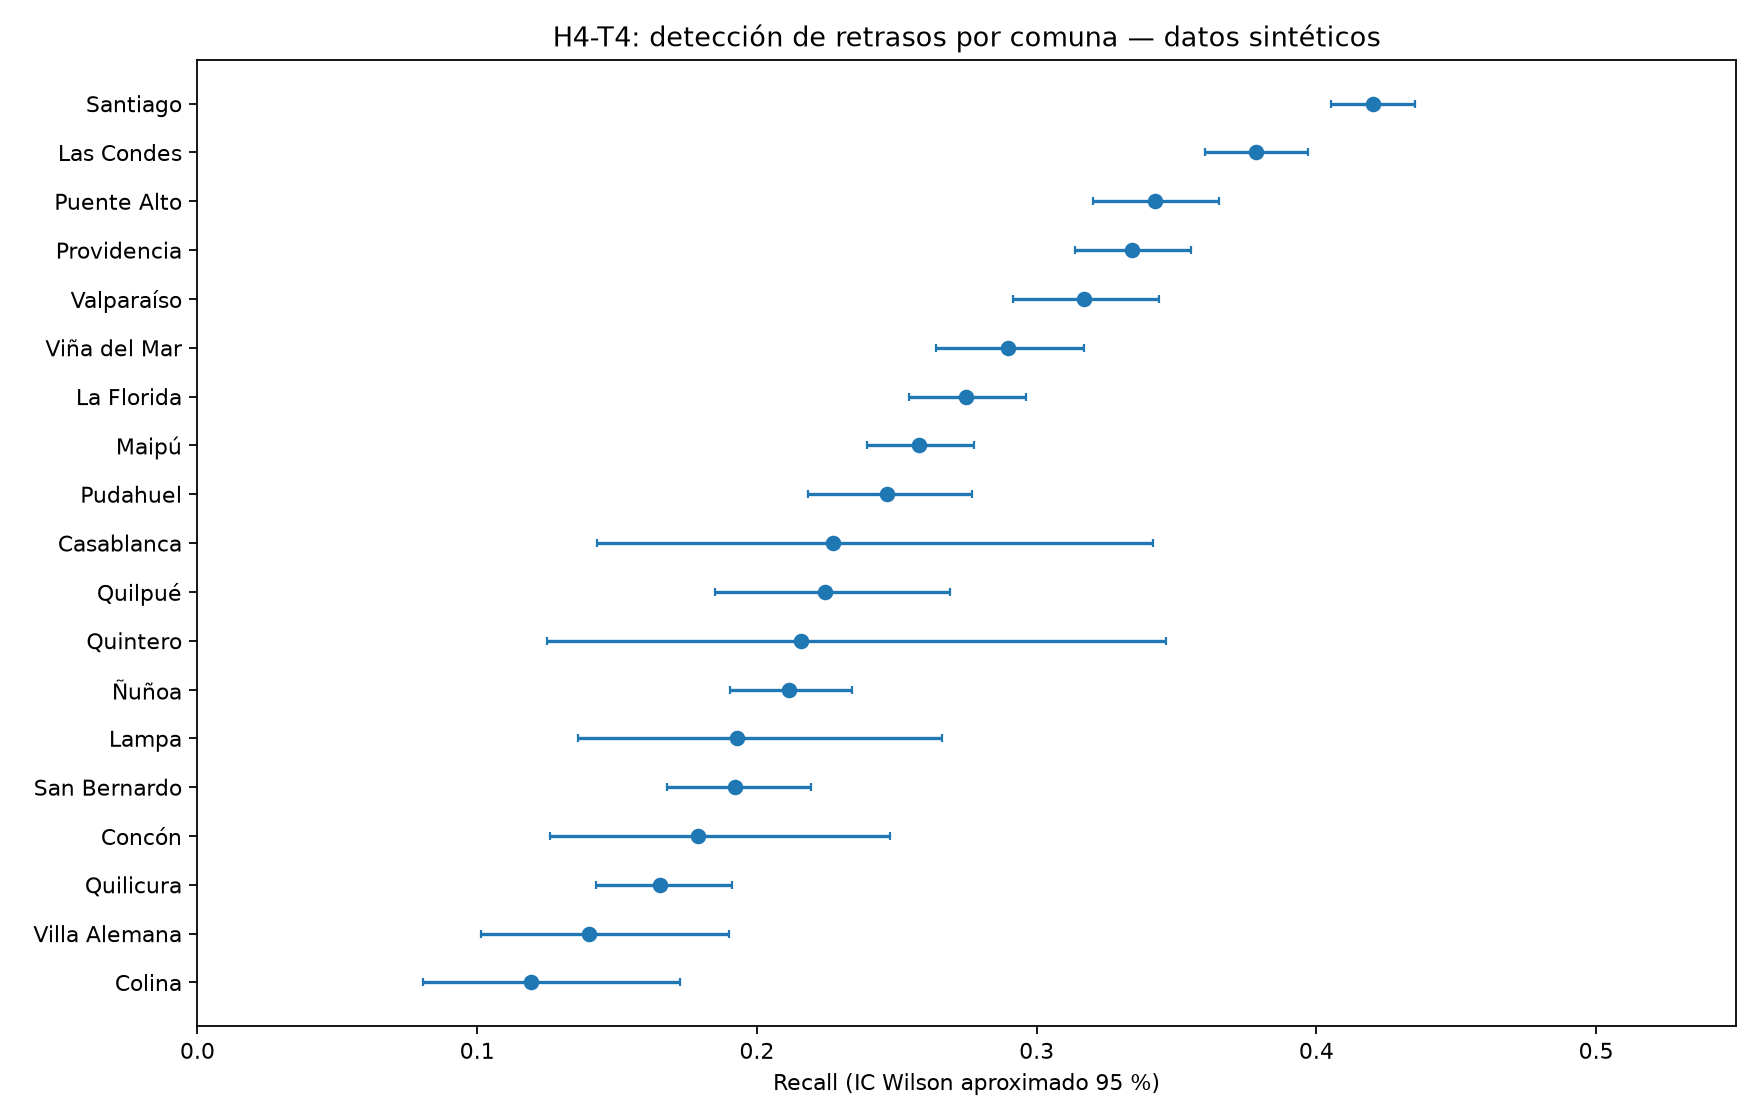

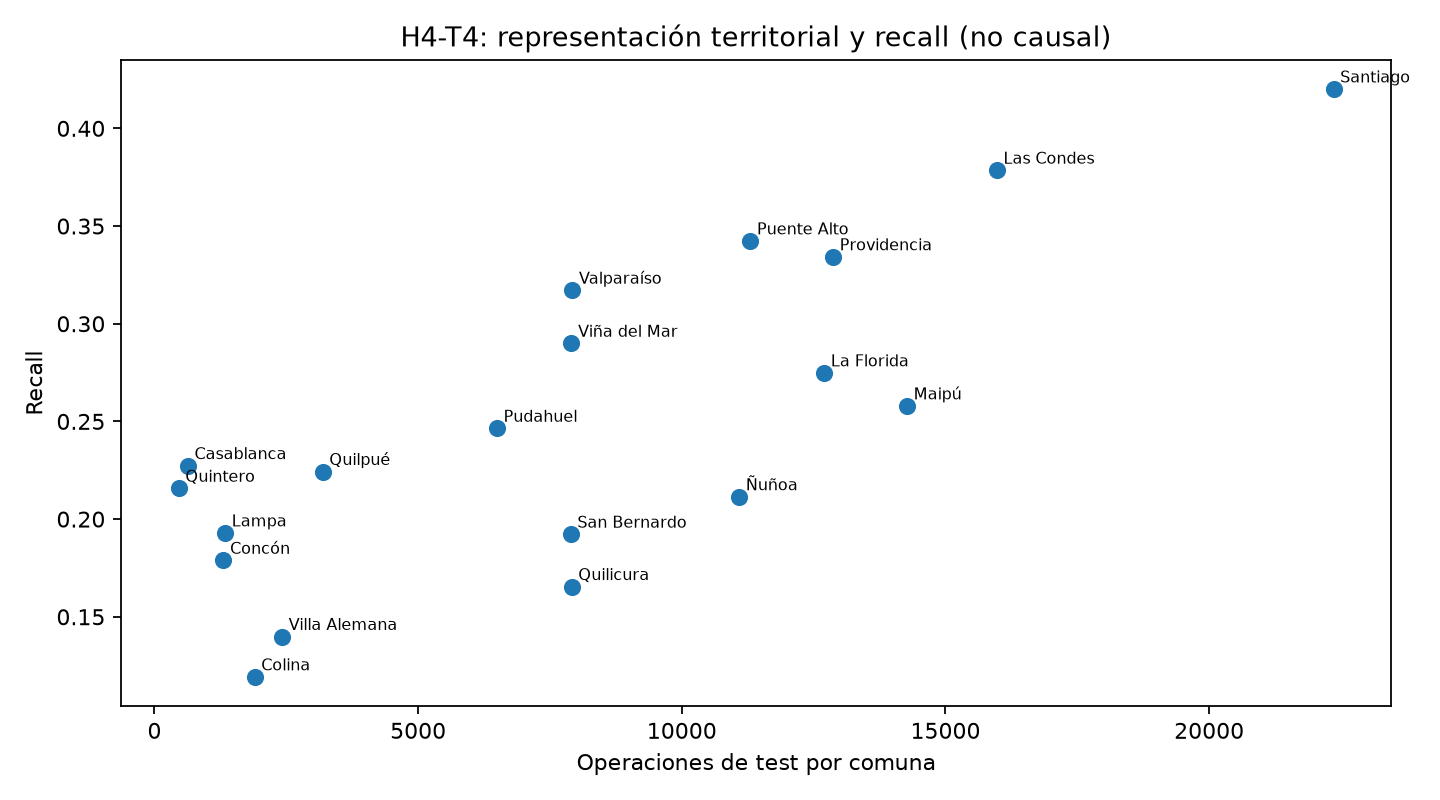

In [59]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
base = Path.cwd()
if base.name == "notebooks": base = base.parent
ruta = base / "output/resultados/sesgos_equidad/diagnostico_sesgos_comunas.csv"
informe_ruta = base / "output/resultados/sesgos_equidad/diagnostico_sesgos.json"
if not ruta.exists() or not informe_ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso sesgos")
tabla_sesgos = pd.read_csv(ruta)
resumen_sesgos = json.loads(informe_ruta.read_text(encoding="utf-8"))
display(tabla_sesgos[["comuna_destino","operaciones","retrasos","recall","recall_ic95_inf","recall_ic95_sup","precision","fpr","muestra_baja_relativa"]].round(3))
print("Brecha descriptiva recall:", resumen_sesgos["brecha_recall_comunas_con_al_menos_30_retrasos"])
for nombre in ["sesgos_recall_comunas.png","sesgos_representacion_recall.png"]:
    display(Image(filename=str(base / "output/graficos" / nombre)))


### Interpretación de resultados y cierre — H4-T4

**Alcance.** Se analizaron **149.935 operaciones sintéticas**, de las cuales **21.795** presentaron retraso, distribuidas en **19 comunas** del conjunto de prueba de agosto–septiembre de 2026. Con el umbral oficial de **0.15** (fijado previamente en validación), el modelo alcanzó **recall global de 30.95 %**, **precision de 34.56 %** y **FPR de 9.97 %**. Esta tarea describe resultados existentes: **no reentrena, no ajusta umbrales ni selecciona el modelo usando test**.

**Disparidades territoriales.** El recall varía entre **42.01 % en Santiago** (4.173 retrasos; 1.753 detectados) y **11.92 % en Colina** (193 retrasos; 23 detectados), una brecha descriptiva de **30.09 puntos porcentuales**. En comunas con varios miles de operaciones persisten resultados bajos: **Ñuñoa 21.14 %** (1.056 retrasos sin alerta) y **Quilicura 16.54 %** (752 retrasos sin alerta). Las diferencias no se limitan a los grupos pequeños. En Santiago, a su vez, la **FPR es 16.90 %**, frente a **4.98 % en Quilicura**: aumentar alertas sin controlar falsos positivos puede incrementar la carga operativa.

**Representación y desbalance.** Entre las 19 comunas se observó una correlación **Spearman = 0.70** entre cantidad de operaciones y recall: asociación descriptiva positiva, **no causal**, que no prueba que la menor representación sea el motivo de menor detección. También varían las tasas base: **18.66 %** de retrasos en Santiago y **11.39 %** en Quilicura. Es necesario considerar diferencias de composición (por ejemplo, distancias y horarios) antes de atribuir disparidades a una causa concreta. La relación con el tamaño tampoco es uniforme: **Quintero** cuenta con 460 operaciones y recall 21.57 %, mientras **Quilicura** tiene 7.911 operaciones y recall 16.54 %.

**Incertidumbre.** Los intervalos de Wilson al 95 % se estiman con el **número de retrasos** como denominador del recall. Son más amplios cuando hay menos casos positivos: **Quintero ~12.49 %–34.63 %** (51 retrasos), frente a **Santiago ~40.52 %–43.51 %** (4.173 retrasos). Deben interpretarse como aproximaciones, porque las operaciones podrían no ser independientes (rutas o conductores compartidos). Todos los grupos analizados tienen al menos 30 retrasos; la etiqueta `muestra_baja_relativa` compara su representación con la mediana de operaciones, **no invalida automáticamente sus métricas**.

**Riesgos y mitigaciones recomendadas:**

1. Revisar calidad y cobertura de datos por **comuna y mes**, priorizando comunas subrepresentadas, sin suponer que añadir filas resolverá el problema por sí solo.
2. Investigar **falsos negativos** y **falsos positivos** en Ñuñoa, Quilicura y Santiago; contrastar distancias, horarios y tasas base de retraso.
3. Monitorear **recall, precision, FPR e intervalos de incertidumbre** por comuna, no solamente la métrica global.
4. Evaluar posibles ajustes de ponderación, muestreo o calibración **solo en entrenamiento y validación cronológica**; no elegir modificaciones con base en el test ya inspeccionado.
5. Utilizar las alertas exclusivamente como **apoyo a decisiones operacionales**, sin evaluaciones o sanciones automáticas de conductores.

**Conclusión de H4-T4.** Se identificaron **diferencias territoriales sustanciales y un riesgo potencial de disparidad en la detección**, junto con una asociación positiva entre representación y recall. **No se ha demostrado discriminación ni causalidad**, y los datos son sintéticos. La evaluación más exhaustiva de equidad y de eventuales mitigaciones se reserva para **H5-T3**, evitando duplicar análisis y sin afirmar mejoras operacionales reales.

**Evidencias:** `src/sesgos.py`, `output/resultados/sesgos_equidad/diagnostico_sesgos.json`, `output/resultados/sesgos_equidad/diagnostico_sesgos_comunas.csv`, `output/graficos/sesgos_recall_comunas.png` y `output/graficos/sesgos_representacion_recall.png`.


## 8. H5-T1 — Evaluación final comparativa en test

Los resultados los genera **únicamente** `python main.py --proceso evaluacion-final` en `src/evaluacion.py`. Esta sección **solo lee los artefactos**: no entrena, recalcula ni ajusta modelos. Se compara Random Forest con la configuración base H4-T1, ajustado con todo el conjunto train y umbral elegido en julio, frente al **XGBoost oficial guardado** de H4-T1. Ambos se evalúan sobre agosto–septiembre de 2026.

**Criterio de selección:** el modelo oficial XGBoost ya se seleccionó en validación (H4-T1); **no se elige un nuevo ganador utilizando test**. Precision, Recall y falsos negativos importan para detectar riesgos, mientras que falsos positivos representan alertas que pueden consumir recursos. El test ya se examinó en fases anteriores; los resultados son descriptivos, no una nueva validación prospectiva. Los datos sintéticos no demuestran reducción real de los retrasos.

,modelo,umbral,roc_auc,pr_auc,precision,recall,f1,tasa_alertas,verdaderos_negativos,falsos_positivos,falsos_negativos,verdaderos_positivos,retrasos_reales,alertas_emitidas,retrasos_detectados,retrasos_no_detectados
0,Random Forest,0.10,0.7021,0.2980,0.2591,0.5753,0.3573,0.3227,92294,35846,9257,12538,21795,48384,12538,9257
1,XGBoost,0.15,0.7074,0.3044,0.3456,0.3095,0.3265,0.1302,115364,12776,15049,6746,21795,19522,6746,15049


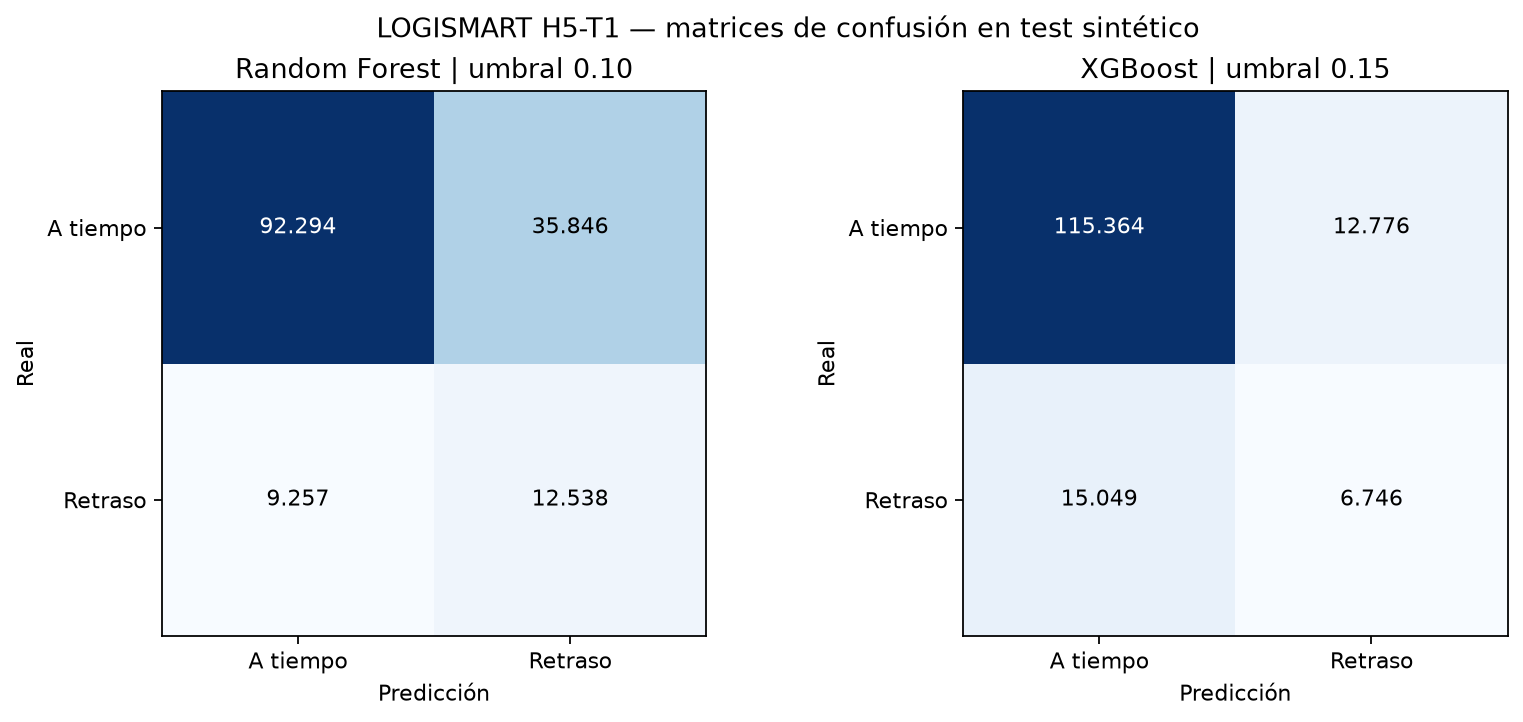

In [60]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
ruta = base / "output/resultados/modelado/evaluacion_final_modelos.json"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta antes: python main.py --proceso evaluacion-final")
final = json.loads(ruta.read_text(encoding="utf-8"))
comparacion = pd.read_csv(base / "output/resultados/modelado/comparacion_modelos_test.csv")
display(comparacion.round(4))
display(Image(filename=str(base / "output/graficos/matrices_confusion_modelos_test.png")))


### Interpretación y cierre — H5-T1 (resultados verificados)

**Diseño de evaluación.** Se analizaron **149.935 operaciones sintéticas** del período **agosto–septiembre de 2026**, con **21.795 retrasos reales** (prevalencia del **14.54 %**). Los modelos comparten el mismo conjunto test y se entrenaron con las **825,299 operaciones** del período de entrenamiento. El modelo **Random Forest** usa la configuración original de H4-T1 y fue reentrenado solo con train; **XGBoost** es el pipeline oficial de H4-T1, cargado sin reentrenamiento. Los umbrales **0.10** y **0.15**, respectivamente, fueron elegidos con **julio de 2026** (validación), no con test. Las configuraciones optimizadas en H4-T3 **no sustituyeron** estos modelos.

**Métricas comparativas.** Random Forest alcanzó **ROC-AUC 0.7021**, **PR-AUC 0.2980**, **precision 25.91 %**, **recall 57.53 %** y **F1 0.3573**. XGBoost logró **ROC-AUC 0.7074**, **PR-AUC 0.3044**, **precision 34.56 %**, **recall 30.95 %** y **F1 0.3265**. XGBoost obtuvo mayor **ROC-AUC, PR-AUC y precision**; Random Forest, mayor **recall y F1**. Las diferencias en precision y recall también dependen de los **umbrales distintos** elegidos previamente en validación.

**Matriz de confusión y errores.** En el orden **[[TN, FP], [FN, TP]]**, Random Forest registra **[[92,294, 35,846], [9,257, 12,538]]**; XGBoost, **[[115,364, 12,776], [15,049, 6,746]]**. Random Forest detectó **12,538** retrasos reales, frente a **6,746** de XGBoost: **5,792 detecciones más** y **5,792 falsos negativos menos**. Como contrapartida, produjo **23,070 falsos positivos adicionales**.

**Carga de alertas.** Random Forest emitió **48,384 alertas** (**32.27 %** de las operaciones); XGBoost emitió **19,522** (**13.02 %**). Así, Random Forest requeriría revisar **28,862 alertas adicionales** en este test. La mayor cobertura de retrasos podría ser útil si el costo de no detectar un atraso fuese elevado; la mayor cantidad de alertas incorrectas también podría sobrecargar al equipo logístico. **No se dispone de costos reales por falso positivo o falso negativo** para cuantificar el beneficio neto.

**Decisión sobre el modelo oficial.** **Se conserva XGBoost como modelo oficial**, porque fue seleccionado previamente en **validación H4-T1** y ofrece una tasa menor de alertas y mejor precision y métricas independientes del umbral (ROC-AUC y PR-AUC). El mayor recall y F1 de Random Forest constituyen un **hallazgo relevante para el negocio**, no una razón para cambiar retrospectivamente de modelo sobre la base del test. Una eventual modificación de umbrales, modelo o estrategia de intervención requeriría una nueva validación temporal y criterios operativos definidos con anterioridad.

**Limitaciones metodológicas y de negocio.** (1) El dataset es **sintético** y estos resultados no establecen desempeño en terreno ni reducción del **20 %** de los retrasos. (2) El test ya se había analizado en H4-T1 y H4-T4; H5-T1 resume una comparación descriptiva, **no una evaluación prospectiva inédita**. (3) Precision y recall dependen de los umbrales, distintos pero elegidos en julio sin consultar test. (4) La selección de XGBoost no se revisa con los resultados de test para evitar sesgo de selección posterior. (5) Alertar sobre una entrega no garantiza que el retraso se evite: sería necesario implementar intervenciones y medir su efecto con datos operativos reales.

**Evidencias verificadas:** `src/evaluacion.py`, `output/resultados/modelado/evaluacion_final_modelos.json`, `output/resultados/modelado/comparacion_modelos_test.csv` y `output/graficos/matrices_confusion_modelos_test.png` (este último se genera localmente con `python main.py --proceso evaluacion-final`).


## 9. H5-T2 — Pruebas de inferencia por lotes (Batch)

El proceso funcional está implementado en `src/batch.py`, invocado con `python main.py --proceso batch`.

**Objetivo:** verificar la escalabilidad local del pipeline de inferencia del **modelo oficial**. Se utilizan distintos volúmenes de operaciones sintéticas, leídos en bloques de tamaño fijo, y se registran tres repeticiones por volumen (salvo modificación explícita de los argumentos CLI). No se entrena ningún modelo ni se ajusta el umbral.

**Qué se mide:** duración de **lectura CSV + preprocesamiento e inferencia**, rendimiento en registros/segundo, segundos de CPU del proceso y RSS máximo del proceso observado por sondeo. No se incluyen carga inicial del modelo, generación del dataset, preparación ETL ni persistencia masiva de predicciones dentro de los tiempos comparados. El RSS contiene todos los componentes del proceso, no solo los del modelo.

**Evidencias:** `output/resultados/batch/batch_rendimiento.json`, `batch_mediciones.csv`, `batch_resumen.csv`, `output/graficos/batch_tiempo.png`, `batch_memoria.png` y `output/batch/predicciones_ejemplo.csv`.

La ventana nocturna aparece en el plan como objetivo operativo, **pero no se presume un SLA numérico**. Solo puede declararse cumplimiento para el volumen y ventana concretos definidos en la prueba. Resultados de desarrollo local no certifican capacidad productiva.

Modelo: XGBoost | Umbral: 0.15000000000000002
Tamaño de bloque: 10000 | Repeticiones: 3


,volumen,mediana_segundos,min_segundos,max_segundos,mediana_filas_por_segundo,mediana_cpu_segundos,max_rss_pico_mb,mediana_rss_incremento_mb
0,1000,0.010,0.010,0.012,97730.693,0.062,279.770,0.020
1,10000,0.035,0.031,0.037,289281.540,0.125,289.477,7.602
2,75000,0.393,0.264,0.408,190614.256,1.422,292.148,7.586
3,150000,0.594,0.573,0.640,252323.097,2.359,294.664,8.672


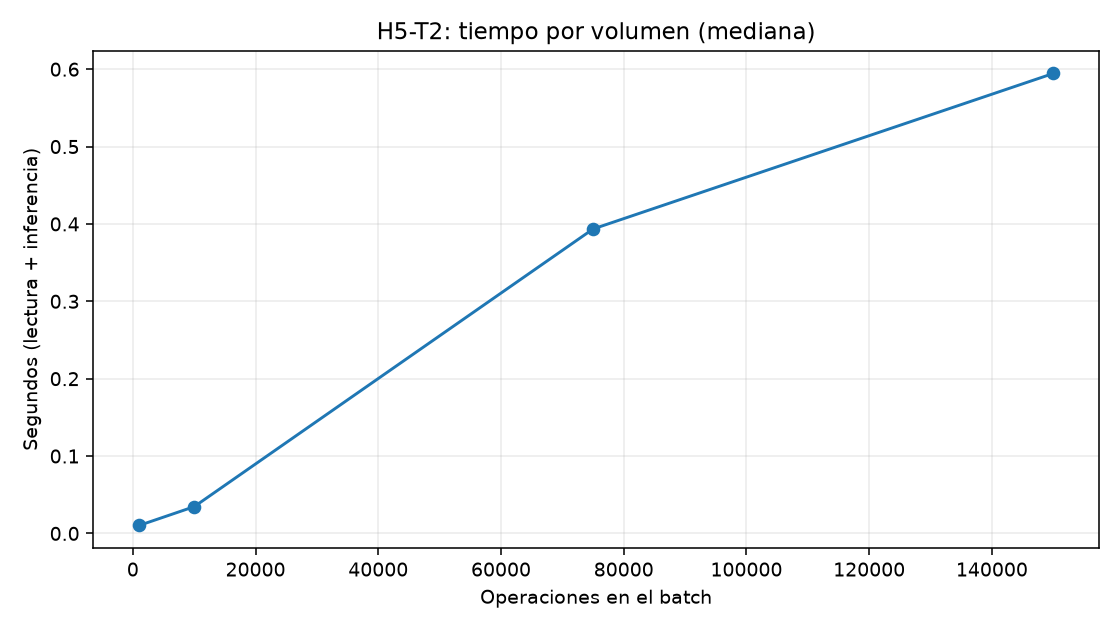

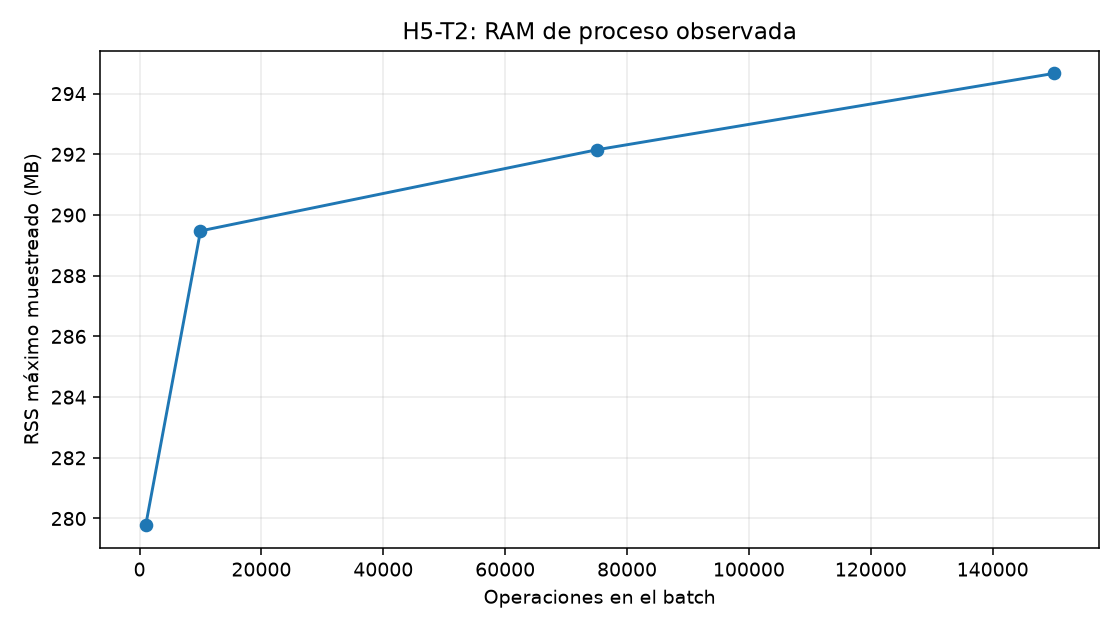

Comprobación de ventana: Sin ventana operativa cuantificada


In [61]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

raiz_h5t2 = Path.cwd()
if raiz_h5t2.name == "notebooks":
    raiz_h5t2 = raiz_h5t2.parent
ruta_batch = raiz_h5t2 / "output/resultados/batch/batch_rendimiento.json"
ruta_tabla = raiz_h5t2 / "output/resultados/batch/batch_resumen.csv"
if not ruta_batch.exists() or not ruta_tabla.exists():
    raise FileNotFoundError("Primero ejecuta: python main.py --proceso batch")
batch = json.loads(ruta_batch.read_text(encoding="utf-8"))
print("Modelo:", batch["modelo"], "| Umbral:", batch["umbral_congelado_en_validacion"])
print("Tamaño de bloque:", batch["tam_lote"], "| Repeticiones:", batch["repeticiones"])
display(pd.read_csv(ruta_tabla).round(3))
for figura in ["batch_tiempo.png", "batch_memoria.png"]:
    ruta = raiz_h5t2 / "output/graficos" / figura
    if ruta.exists():
        display(Image(filename=str(ruta)))
print("Comprobación de ventana:", batch["ventana_operacional"] or "Sin ventana operativa cuantificada")

### Interpretación y cierre — H5-T2 (resultados medidos en desarrollo)

**Entorno y método.** El benchmark del modelo **XGBoost oficial** se ejecutó en **Windows, Python 3.11.9, 16 CPU lógicas y 31.92 GB de RAM**. Se procesaron **1.000, 10.000, 75.000 y 150.000** operaciones sintéticas, con **tres repeticiones por volumen** y bloques de **10.000 filas**. El umbral de decisión **0,15**, fijado anteriormente en validación, permaneció sin cambios. No se utilizaron las etiquetas reales de retraso ni se reentrenó el modelo.

**Tiempos y escalabilidad.** Las **medianas** de ejecución (lectura CSV + preprocesamiento + `predict_proba`, con modelo ya cargado y calentado) fueron: **0,0102 s** para **1.000**, **0,0346 s** para **10.000**, **0,3935 s** para **75.000** y **0,5945 s** para **150.000 operaciones**. En la carga de **75.000**, semejante al volumen mensual simulado, la mediana fue de **0.393 s**, a **190,614 operaciones/s**. Para **150.000**, la mediana fue **0.594 s**, a **252,323 operaciones/s**. Los tiempos totales crecieron al aumentar el volumen, pero el rendimiento por segundo **no fue monótono**: en 75.000 operaciones se registró una mediana de **190.614 ops/s**, inferior a las **252.323 ops/s** de 150.000; las sobrecargas de ejecución y el entorno local pueden influir en el resultado.

**Variabilidad entre repeticiones.** A **75.000 filas**, los tiempos oscilaron entre **0,2642 s y 0,4079 s**, una variación apreciable frente a la mediana. A **150.000**, oscilaron entre **0,5730 s y 0,6399 s**. Tres repeticiones son suficientes para esta evidencia exploratoria, **no para establecer garantías de latencia o capacidad en producción**. No se realizó análisis controlado de concurrencia, cache ni interferencia de otros procesos.

**Memoria y CPU.** El **RSS máximo observado del proceso** fue **279,77 MB** con 1.000 operaciones y **294,66 MB** con 150.000 (diferencia de **14,89 MB** entre los máximos reportados). Para 150.000 operaciones, la **mediana del incremento observado de RSS** fue **8,67 MB**. Estos valores **no son memoria exclusiva de la inferencia**: incluyen intérprete, bibliotecas, modelo y asignaciones acumuladas; el sondeo cada ~20 ms puede perder picos breves. En el escenario de 150.000 operaciones la mediana de CPU acumulada fue **2,359 s**, superior al tiempo real de pared debido a que `time.process_time()` contabiliza los hilos del proceso; **no indica porcentaje de CPU**.

**Lectura operativa.** En este equipo de desarrollo, las pruebas completaron los cuatro volúmenes, incluyendo 150.000 operaciones, sin modificar el modelo oficial. Los resultados sugieren que **la inferencia batch, una vez cargado el modelo, no constituye un cuello de botella evidente** a estos tamaños. Sin embargo, el parámetro `ventana_operacional` no fue definido (**`null`**), por lo que **no puede afirmarse formalmente que se cumple una ventana nocturna específica**.

**Límites del experimento y acciones recomendadas.** El tiempo medido **no incluye** arranque/carga del modelo, generación o preparación ETL, escritura masiva de predicciones, subida a almacenamiento remoto, concurrencia ni fallos/reintentos. Tampoco valida infraestructura productiva. La siguiente validación operacional debe medir el **flujo extremo a extremo**, con persistencia real, varios tamaños de lote, duración concreta de la ventana nocturna y registros de fallas y reintentos. Estas extensiones corresponden al trabajo posterior de automatización, **no a repetir el entrenamiento en H5-T2**.

**Conclusión H5-T2.** Se cumplen los criterios de implementación batch, ensayo de múltiples tamaños, registro de tiempos, CPU y memoria y documentación de limitaciones **en entorno de desarrollo**. No se infiere reducción real de retrasos ni cumplimiento de un SLA no definido. Evidencias verificadas: `output/resultados/batch/batch_rendimiento.json` y `output/resultados/batch/batch_resumen.csv`; los gráficos `batch_tiempo.png` y `batch_memoria.png` se mantienen en la ejecución local.


## 10. H5-T3 — Auditoría formal de equidad territorial

Esta etapa profundiza el diagnóstico H4-T4 con **Precision, Recall, FPR, FNR, falsos negativos y su incertidumbre** por comuna, comparaciones de dos **regiones** (Metropolitana y Valparaíso) y segmentos según representación territorial en **test**. Se ejecuta con `python main.py --proceso equidad` y reutiliza `auditoria_comunas_test.json`.

**Diferencia con H4-T4:** no repite el entrenamiento ni las predicciones; contrasta tasas de error y carga de alertas, agrega por región a partir de conteos, identifica sectores que requieren inspección y documenta las acciones correctivas.

**Control metodológico:** el umbral del XGBoost oficial sigue siendo **0,15** (elegido previamente en julio). El test de agosto–septiembre es un conjunto *ya examinado* en actividades anteriores: las comparaciones son descriptivas, no una nueva validación independiente ni una prueba de causalidad/discriminación. Los intervalos Wilson son aproximados y no ajustan por agrupación de observaciones o comparaciones múltiples.

Métricas globales:


,Valor
operaciones,149935.000000
retrasos,21795.000000
falsos_negativos,15049.000000
falsos_positivos,12776.000000
recall_global,0.309521
precision_global,0.345559
fpr_global,0.099703
spearman_operaciones_recall,0.700000


Comparación regional:


,zona,operaciones,retrasos,recall,precision,fpr,fn
0,Región Metropolitana,126092,18576,0.3157,0.3444,0.1038,12711
1,Región de Valparaíso,23843,3219,0.2737,0.3532,0.0782,2338


Representación por comuna (agrupada según mediana de test):


,representacion_test,operaciones,retrasos,recall,precision,fpr
0,Bajo mediana,25636,2939,0.2031,0.3241,0.0549
1,Igual o sobre mediana,124299,18856,0.3261,0.3478,0.1094


Comunas con menor recall:


,comuna_destino,zona,operaciones,retrasos,recall,recall_ic95_inf,recall_ic95_sup,precision,fpr,fn,fp
14,Colina,Región Metropolitana,1899,193,0.1192,0.0807,0.1725,0.2500,0.0404,170,69
13,Villa Alemana,Región de Valparaíso,2419,236,0.1398,0.1013,0.1899,0.3333,0.0302,203,66
8,Quilicura,Región Metropolitana,7911,901,0.1654,0.1425,0.1910,0.2992,0.0498,752,349
16,Concón,Región de Valparaíso,1308,151,0.1788,0.1259,0.2477,0.3803,0.0380,124,44
10,San Bernardo,Región Metropolitana,7893,895,0.1922,0.1677,0.2193,0.3127,0.0540,723,378
15,Lampa,Región Metropolitana,1339,140,0.1929,0.1361,0.2661,0.2967,0.0534,113,64
6,Ñuñoa,Región Metropolitana,11088,1339,0.2114,0.1903,0.2340,0.3325,0.0583,1056,568
18,Quintero,Región de Valparaíso,460,51,0.2157,0.1249,0.3463,0.3438,0.0513,40,21


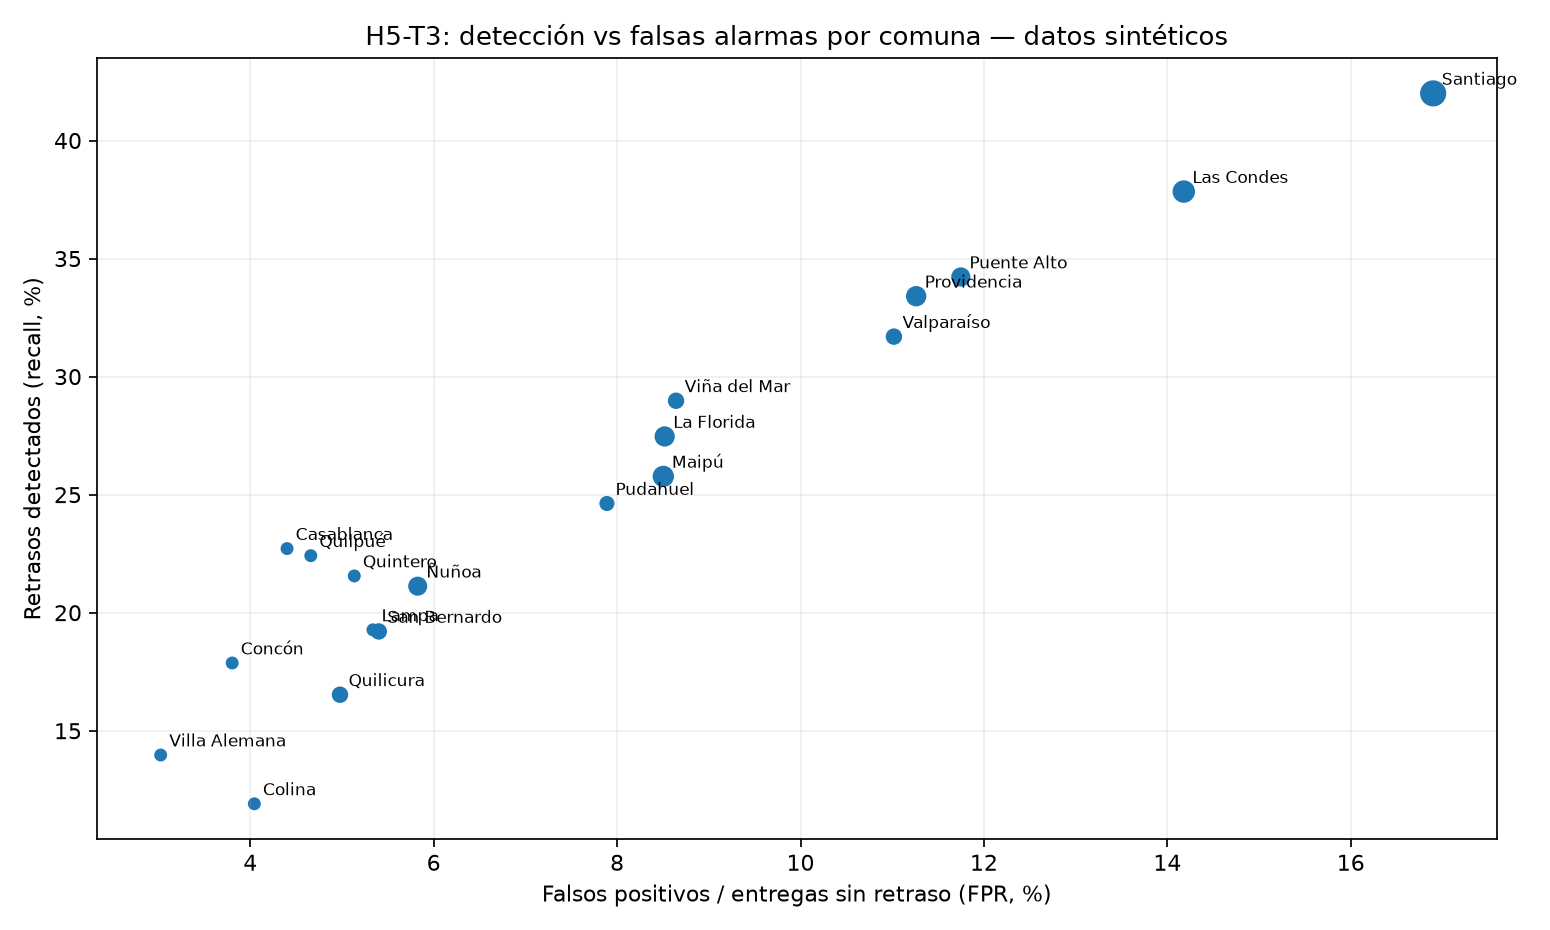

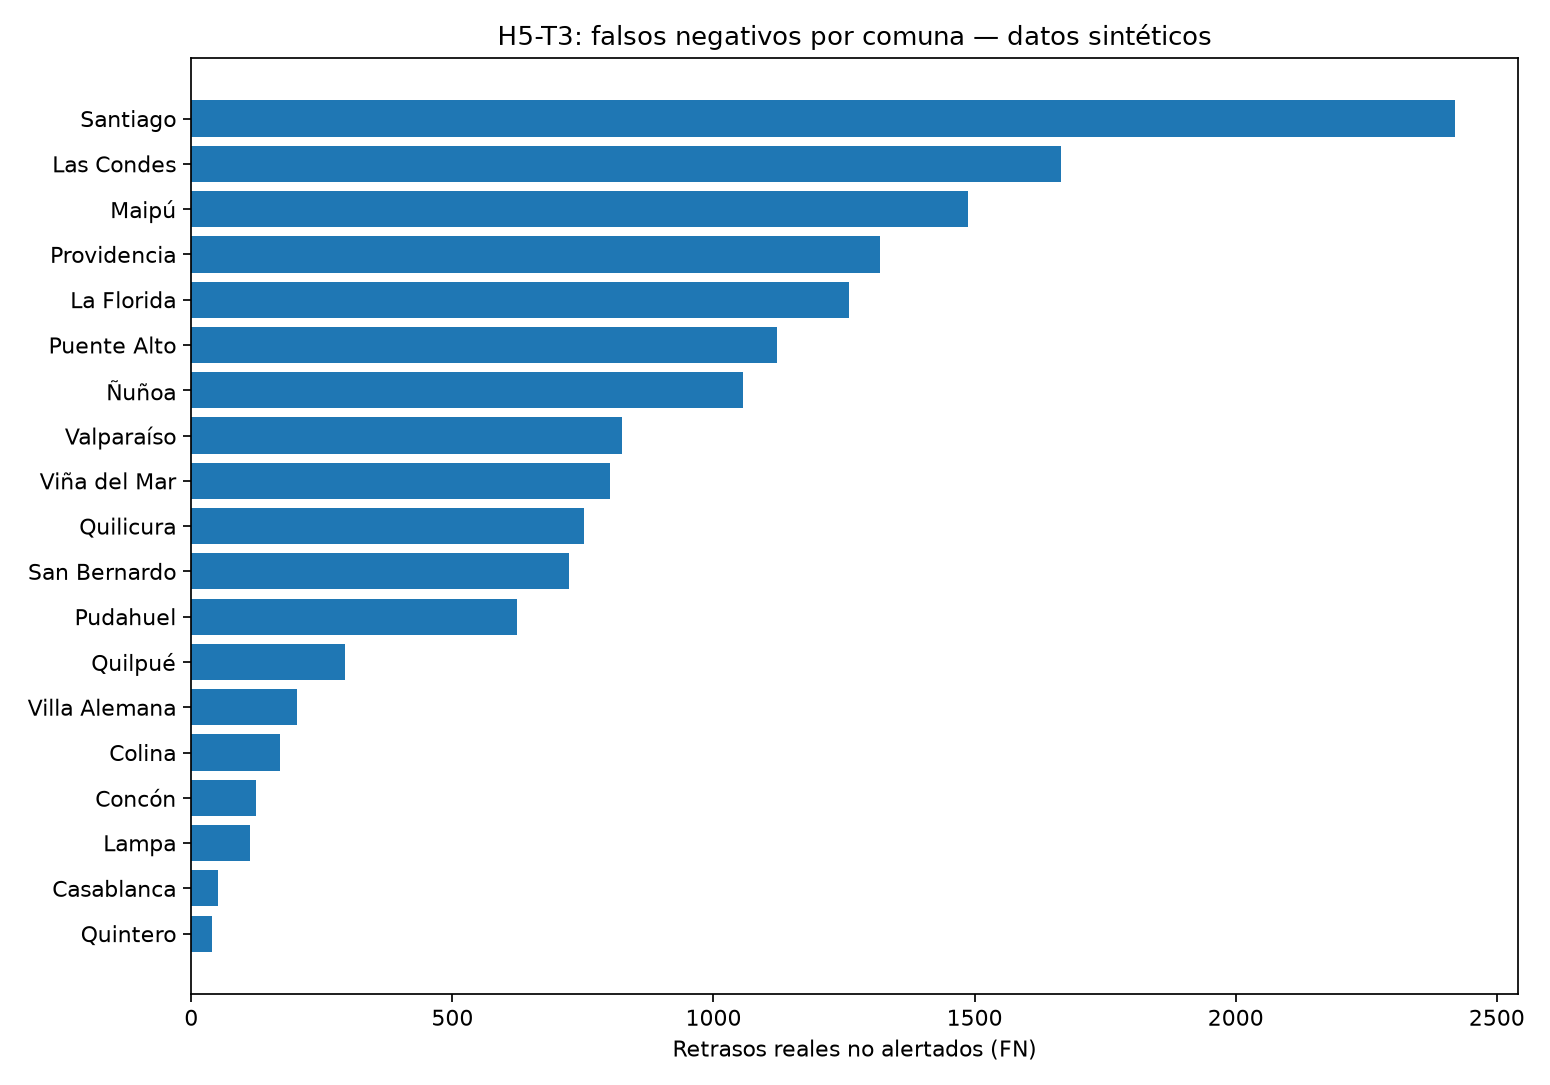

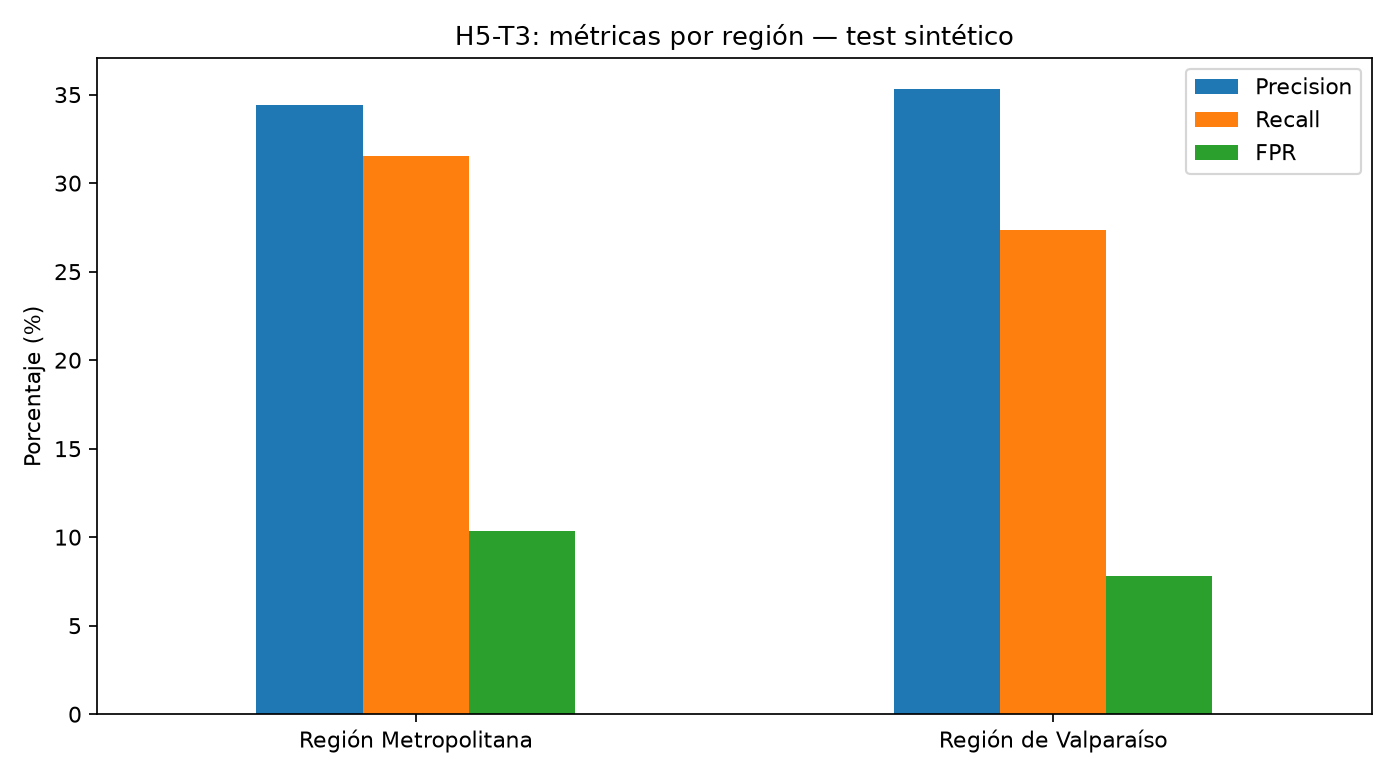

In [62]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

raiz_h5t3 = Path.cwd()
if raiz_h5t3.name == "notebooks":
    raiz_h5t3 = raiz_h5t3.parent
r = raiz_h5t3 / "output/resultados/sesgos_equidad"
g = raiz_h5t3 / "output/graficos"
ruta = r / "equidad_territorial.json"
if not ruta.is_file():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso equidad")

info_equidad = json.loads(ruta.read_text(encoding="utf-8"))
por_comuna = pd.read_csv(r / "equidad_comunas.csv")
por_zona = pd.read_csv(r / "equidad_zonas.csv")
representacion = pd.read_csv(r / "equidad_representacion_test.csv")
print("Métricas globales:")
display(pd.Series({k: info_equidad[k] for k in [
    "operaciones", "retrasos", "falsos_negativos", "falsos_positivos",
    "recall_global", "precision_global", "fpr_global",
    "spearman_operaciones_recall"]}).to_frame(name="Valor"))
print("Comparación regional:")
display(por_zona[["zona", "operaciones", "retrasos", "recall", "precision", "fpr", "fn"]].round(4))
print("Representación por comuna (agrupada según mediana de test):")
display(representacion[["representacion_test", "operaciones", "retrasos", "recall", "precision", "fpr"]].round(4))
print("Comunas con menor recall:")
display(por_comuna.sort_values("recall").loc[:, [
    "comuna_destino", "zona", "operaciones", "retrasos", "recall", "recall_ic95_inf",
    "recall_ic95_sup", "precision", "fpr", "fn", "fp"]].head(8).round(4))
for nombre in ["equidad_recall_vs_fpr.png", "equidad_falsos_negativos.png", "equidad_comparacion_zonas.png"]:
    imagen = g / nombre
    if imagen.is_file():
        display(Image(filename=str(imagen)))

### Lectura crítica y mitigación — H5-T3

- **Disparidades:** las diferencias en Recall y FPR deben analizarse conjuntamente: detectar más retrasos también puede incrementar falsas alarmas. Revisar tanto las tasas por comuna como el volumen absoluto de falsos negativos y la prevalencia de retrasos.
- **Representación:** la correlación de Spearman obtenida en H4-T4 (0,70) es una **asociación descriptiva entre 19 comunas**. Los segmentos de baja/alta representación se definen usando *test*, por lo que no miden el desbalance de *train* ni prueban su efecto causal.
- **Incertidumbre:** en comunas pequeñas, las tasas pueden ser inestables. Los IC de Wilson ilustran incertidumbre binomial aproximada; las banderas de revisión no son pruebas estadísticas de discriminación.
- **Rebalanceo:** **no se aplicó una técnica previamente**, por lo que no corresponde afirmar que fue efectiva. Una prueba futura debe hacerse exclusivamente en *train* y compararse en validación temporal, sin ajustar con resultados de *test*.
- **Medidas propuestas:** revisar cobertura/etiquetas por comuna y mes, estratificar por distancia y horario, monitorear Precision/Recall/FPR, validar ponderación solo con train y usar alertas exclusivamente como apoyo logístico (nunca para sanciones automáticas).
- **Alcance:** el informe Markdown y las tablas exportadas en `output/resultados/sesgos_equidad/` constituyen la evidencia formal de H5-T3. Las cifras corresponden a **datos sintéticos** y no garantizan equidad en operaciones reales.

**Resultados verificados (agregados H4-T4, contrastados con H5-T1):** la Región Metropolitana registró **126.092 operaciones** (recall **31,57 %**, precision **34,44 %**, FPR **10,38 %**, **12.711** falsos negativos); la Región de Valparaíso registró **23.843 operaciones** (recall **27,37 %**, precision **35,32 %**, FPR **7,82 %**, **2.338** falsos negativos). Las comunas bajo la mediana de operaciones de test tuvieron recall **20,31 %** frente a **32,61 %** en las demás; sus FPR fueron **5,49 %** y **10,94 %**, respectivamente. Es un hallazgo descriptivo, no una explicación causal. Si se regeneran los datos, estos valores narrativos deben revisarse.


## 11. H5-T4 — Validación conceptual de negocio y umbrales de alerta

Esta etapa traduce las métricas técnicas a decisiones operacionales. El proceso reproducible está implementado en `src/validacion_negocio.py` y se ejecuta con `python main.py --proceso validacion-negocio`. **El notebook solo lee las evidencias generadas**, no recalcula las probabilidades ni modifica el modelo.

Se contrastan **tres escenarios de julio de 2026** (validación): `0.10` maximiza cobertura frente a más alertas, **`0.15` es el umbral oficial seleccionado previamente mediante F1**, y `0.20` reduce la carga de revisión, a costa de omitir más retrasos.

Los niveles de riesgo propuestos son prioridades de revisión para el **equipo humano**: bajo (`p < 0.10`), observación (`0.10 ≤ p < 0.15`) y prioritario (`p ≥ 0.15`). *Prioritario* no significa que el riesgo absoluto sea elevado: el modelo tiene Precision de alrededor del 26 % en julio al umbral oficial.

Los resultados **no equivalen a una validación real de la Gerencia de Operaciones**, no acreditan la meta de reducción de retrasos del 20 % y no miden capacidad operacional real. Las diferencias territoriales detectadas en H5-T3 deben monitorearse antes de usar el sistema como apoyo a decisiones.

,escenario,umbral,precision,recall,f1,tasa_alertas,alertas_validacion,alertas_diarias_promedio,verdaderos_positivos,falsos_positivos,falsos_negativos,cabe_en_capacidad_simulada
0,Mayor cobertura,0.10,0.2152,0.7124,0.3306,0.4557,34070,1099.03,7333,26737,2960,NaN
1,Oficial: equilibrio de F1,0.15,0.2616,0.5232,0.3488,0.2753,20581,663.90,5385,15196,4908,NaN
2,Menos alertas,0.20,0.3107,0.3444,0.3267,0.1526,11409,368.03,3545,7864,6748,NaN


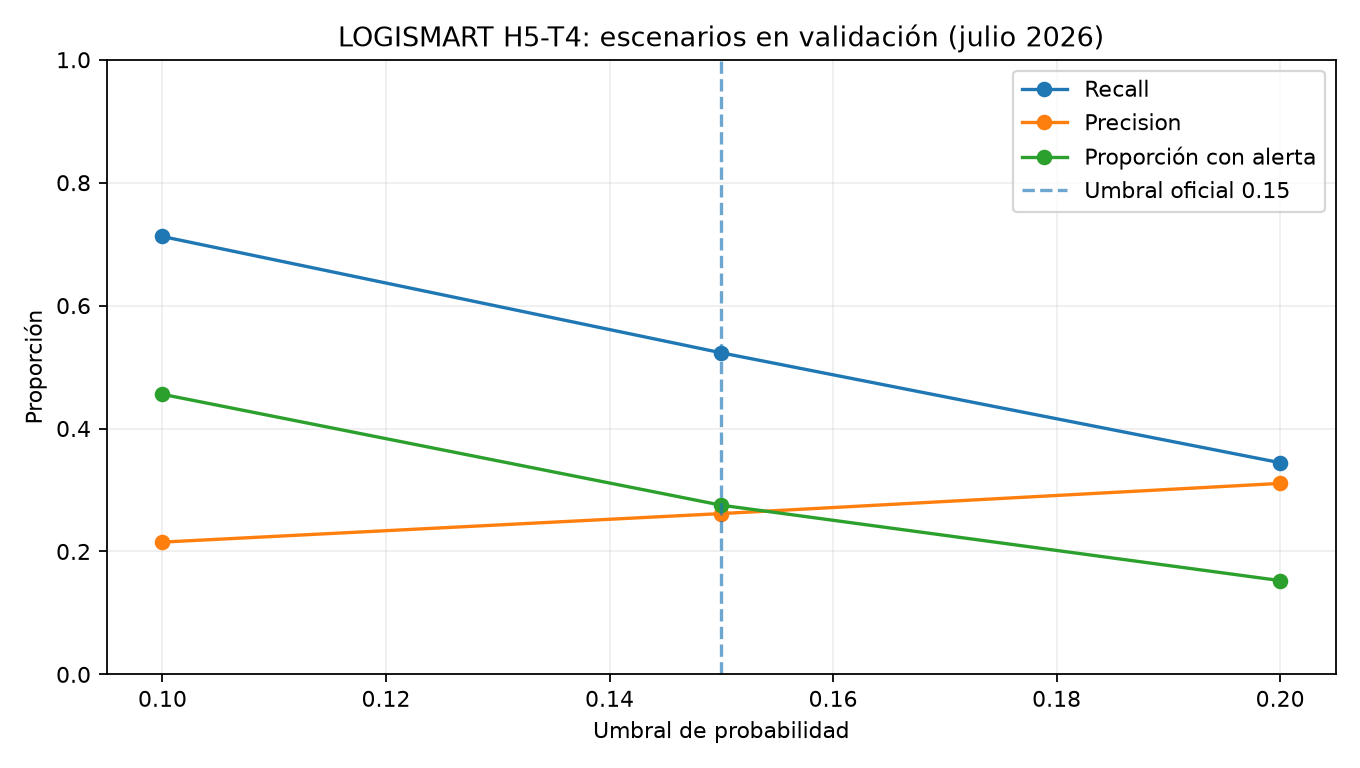

Niveles: 


,regla,operaciones_validacion,accion
bajo,p < 0.10,40696,No priorizar automáticamente; seguimiento normal
observacion,0.10 <= p < umbral_oficial,13489,Revisión contextual si hay disponibilidad
prioritario,p >= umbral_oficial,20581,Revisión humana preventiva de la entrega


Estado de validación gerencial: No realizada; únicamente simulación conceptual fundamentada en los requerimientos


In [63]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

raiz_h5t4 = Path.cwd()
if raiz_h5t4.name == "notebooks":
    raiz_h5t4 = raiz_h5t4.parent
ruta_resumen_h5t4 = raiz_h5t4 / "output/resultados/negocio/validacion_negocio.json"
ruta_tabla_h5t4 = raiz_h5t4 / "output/resultados/negocio/validacion_negocio_umbrales.csv"
ruta_figura_h5t4 = raiz_h5t4 / "output/graficos/validacion_negocio_umbrales.png"
if not all(p.exists() for p in (ruta_resumen_h5t4, ruta_tabla_h5t4, ruta_figura_h5t4)):
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso validacion-negocio")
resumen_h5t4 = json.loads(ruta_resumen_h5t4.read_text(encoding="utf-8"))
tabla_h5t4 = pd.read_csv(ruta_tabla_h5t4)
display(tabla_h5t4.round(4))
display(Image(filename=str(ruta_figura_h5t4)))
print("Niveles: ")
display(pd.DataFrame(resumen_h5t4["niveles_riesgo"]).T)
print("Estado de validación gerencial:", resumen_h5t4["validacion_gerencia"])


### Interpretación y cierre — H5-T4 (resultados verificados)

**Método y alcance.** Se realizó una **validación conceptual**, no una aprobación por una gerencia real. Los tres escenarios provienen de las **74.766 operaciones sintéticas de julio de 2026** (conjunto de validación), usando la curva de umbrales registrada previamente. El modelo **XGBoost oficial** y su umbral de alerta **0,15** se conservaron sin reajustes; **no se utilizaron los datos de test** para elegir una política nueva.

| Escenario | Umbral | Precision | Recall | Alertas en julio | FP | FN | Alertas/día* |
|---|---:|---:|---:|---:|---:|---:|---:|
| Mayor cobertura | 0,10 | 21,52 % | 71,24 % | 34.070 | 26.737 | 2.960 | 1.099,03 |
| **Oficial: equilibrio de F1** | **0,15** | **26,16 %** | **52,32 %** | **20.581** | **15.196** | **4.908** | **663,90** |
| Menos alertas | 0,20 | 31,07 % | 34,44 % | 11.409 | 7.864 | 6.748 | 368,03 |

*Promedio sobre **31 días calendario**; no representa jornadas efectivas de trabajo ni picos horarios.*

**Compromiso de negocio.** El escenario 0,10 recupera **1.948 retrasos adicionales** frente al umbral 0,15 (7.333 frente a 5.385 verdaderos positivos), pero genera **11.541 falsos positivos adicionales** (26.737 frente a 15.196). El umbral 0,20 reduce las alertas totales en **9.172**, pero deja **1.840 retrasos adicionales sin detectar** (6.748 frente a 4.908 falsos negativos). Sin una estimación verificable de costo por revisión, capacidad de personal, tiempos de respuesta y consecuencias de omitir un retraso, no puede declararse un umbral económicamente óptimo.

**Niveles propuestos para priorización humana:** **bajo** si `p < 0.10` (**40.696** operaciones), **observación** si `0.10 <= p < 0.15` (**13.489**) y **prioritario** si `p >= 0.15` (**20.581**). Estas categorías expresan **prioridad relativa de revisión**, no una clasificación de probabilidades altas en términos absolutos. Las alertas deben ser revisadas por operaciones; **no se usan para sancionar automáticamente conductores**.

**Decisión y restricciones.** Se mantiene provisionalmente **XGBoost con umbral 0,15**, fijado por F1 en validación. Aun así, las **663,90 alertas diarias promedio** del escenario oficial podrían superar la capacidad real de LOGISMART; **esa capacidad no fue informada ni validada**. Antes de un despliegue habría que acordar dotación disponible, costos, SLA, frecuencia de revisión, acciones preventivas, seguimiento por comuna y un responsable humano.

**Limitaciones.** Los datos son sintéticos y la validación es conceptual; la Gerencia de Operaciones **no ha aprobado** la propuesta. Las brechas territoriales de H5-T3 requieren supervisión. La meta de **reducir retrasos 20 %** sigue siendo un objetivo y **no un resultado observado**: para comprobarla se necesitarían intervenciones operacionales y un diseño de evaluación de impacto independiente.

**Evidencias:** `output/resultados/negocio/validacion_negocio.json` (resultados estructurados), `output/resultados/negocio/validacion_negocio_umbrales.csv` (tabla comparativa), `output/resultados/negocio/reporte_validacion_negocio.md` (informe ejecutivo) y `output/graficos/validacion_negocio_umbrales.png` (visualización). **El `.md` no sustituye al `.csv`**: cumple una función documental complementaria.

## 12. H6-T1 — Automatización local de preparación, inferencia y respaldos

La ejecución funcional se encuentra en `src/automatizacion.py` y se invoca con `python main.py --proceso automatizar`. Reutiliza las implementaciones existentes de H3-T4 (`preparar_datos`) y H5-T2 (`predecir_lotes`), sin reentrenar ni modificar el umbral oficial.

**Alcance:** demostración local sobre el CSV histórico sintético. Guarda predicciones, una bitácora JSON por ejecución y un respaldo ZIP local verificable mediante CRC y SHA-256. **PostgreSQL y S3 están fuera del alcance de la EV3**. No hay ejecución nocturna programada ni validación sobre nuevos datos sin etiqueta: son limitaciones operativas, no requisitos declarados de esta entrega.

**Para producir las evidencias:** primero ejecutar `python main.py --proceso automatizar --max-filas-automatizacion 20000` desde la raíz. La celda siguiente **solo lee** las evidencias de la última corrida, no inicia el pipeline ni vuelve a inferir.

In [64]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

raiz_h6t1 = Path.cwd()
if raiz_h6t1.name == "notebooks":
    raiz_h6t1 = raiz_h6t1.parent
registros_h6t1 = sorted((raiz_h6t1 / "output/ejecuciones").glob("*/registro.json"))
if not registros_h6t1:
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso automatizar --max-filas-automatizacion 20000")
ultimo_h6t1 = registros_h6t1[-1]
registro_h6t1 = json.loads(ultimo_h6t1.read_text(encoding="utf-8"))
print("Corrida:", registro_h6t1["identificador_ejecucion"])
print("Estado:", registro_h6t1["estado"])
print("Etapas:")
display(pd.DataFrame.from_dict(registro_h6t1.get("etapas", {}), orient="index"))
if registro_h6t1["estado"] == "completado":
    print("Resultados:", registro_h6t1["resultados"])
    print("Respaldo:", registro_h6t1["respaldo"])
    display(pd.read_csv(ultimo_h6t1.parent / "predicciones.csv", nrows=10))
else:
    print("Error registrado:", registro_h6t1.get("error", {}))

Corrida: 20261104T170000050763Z_a51e87
Estado: completado
Etapas:


,segundos,filas
carga_modelo,0.1155,NaN
preparacion,13.4479,1050000.0
inferencia,6.2576,1050000.0


Resultados: {'filas_procesadas': 1050000, 'alertas_emitidas': 161875, 'tasa_alertas': 0.15416666666666667, 'umbral_oficial': 0.15000000000000002, 'archivo_predicciones': 'output\\ejecuciones\\20261104T170000050763Z_a51e87\\predicciones.csv', 'sha256_predicciones': '5c55399e0c79e171a15c84c47096721f91fc7e63bc786db864a7e0b346031a6e'}
Respaldo: {'ruta': 'output\\respaldos\\20261104T170000050763Z_a51e87.zip', 'verificado': True}


,fila_csv,probabilidad_retraso,alerta_retraso
0,1,0.031264,0
1,2,0.034710,0
2,3,0.087682,0
3,4,0.142711,0
4,5,0.220915,1
5,6,0.125619,0
6,7,0.083657,0
7,8,0.133461,0
8,9,0.029542,0
9,10,0.090704,0


### Interpretación y cierre — H6-T1 (ejecución local completa verificada)

**Ejecución y alcance.** El **4 de noviembre de 2026**, la corrida `20261104T170000050763Z_a51e87` terminó con estado **`completado`** mediante `python main.py --proceso automatizar`. Se procesaron **1.050.000 operaciones sintéticas históricas** (preparación: 25 columnas; modelado: 19), preservando los nulos de `experiencia_conductor_anios` (**15.808**) y `peso_kg` (**10.573**) para imputación interna del pipeline del modelo. Se utilizó el XGBoost oficial con umbral **0,15**, sin reentrenarlo ni modificar su configuración.

**Resultados.** Se exportaron **1.050.000 predicciones** y **161.875 alertas**, una **tasa de alertas de 15,42 %**. Este porcentaje describe la proporción de registros que activan una alerta; **no** es tasa real de retrasos, precision, recall ni una reducción de retrasos. La ejecución incluye train, validación y test históricos; **no constituye predicción prospectiva ni evaluación adicional sobre datos independientes**. Los registros se emplearon como demostración funcional de un pipeline, no para medir desempeño real de negocio.

**Tiempos de la corrida.** La bitácora registró **0,1155 s** de carga del modelo, **13,4479 s** de preparación y **6,2576 s** de inferencia batch. La duración total consignada fue **19,8873 s sin incluir el respaldo**. Estos tiempos corresponden al entorno local y **no certifican capacidad nocturna ni SLA de producción**.

**Integridad y persistencia.** La corrida guardó `predicciones.csv` y `registro.json` bajo `output/ejecuciones/20261104T170000050763Z_a51e87/` y consignó un respaldo ZIP local verificado. En la revisión independiente del **CSV adjuntado** se comprobó: exactamente **1.050.000 filas**, numeración consecutiva de `fila_csv` de 1 a 1.050.000, **ningún valor nulo**, **cero discrepancias** entre `probabilidad_retraso >= 0,15` y `alerta_retraso`, **161.875 alertas** y concordancia exacta del SHA-256 `5c55399e0c79e171a15c84c47096721f91fc7e63bc786db864a7e0b346031a6e` con `registro.json`. El ZIP de respaldo **no fue adjuntado a esta revisión**, por lo que su contenido no se verificó independientemente; se registra la verificación reportada por el propio programa.

**Evaluación de aceptación.** Quedan demostrados localmente el flujo **preparación → inferencia batch → almacenamiento CSV → bitácora JSON → respaldo ZIP**, el registro de tiempos y una ejecución completa exitosa. Las cuatro pruebas nuevas del prototipo se ejecutaron anteriormente con un modelo simulado; la corrida actual demuestra que el flujo funciona con el modelo oficial. La documentación del proyecto proporciona instrucciones de ejecución y restauración.

**Pendientes y limitaciones.** **PostgreSQL y Amazon S3 no son requisitos de esta EV3**; el respaldo es local, sin copia externa, política de retención automatizada ni planificador nocturno. El CSV de entrada es un histórico **sintético etiquetado** utilizado durante la preparación; la inferencia no lee el objetivo. La solución local constituye el alcance acordado para H6-T1 en la EV3, sin implicar integración productiva. En el informe final de gestión se debe registrar la desviación previa de GitHub Actions (dependencias de CI incompletas) y la acción correctiva aplicada en la ejecución #16.


## 13. H6-T2 — Visualización de alertas e indicadores (prototipo local)

**Implementación funcional:** `src/visualizacion.py`, ejecutada mediante `python main.py --proceso visualizar`. Esta sección **no recalcula predicciones ni duplica la lógica visual**: únicamente lee los artefactos del proceso y muestra el panel/gráficos resultantes.

El prototipo HTML es una evidencia disponible para la Issue H6-T2; **la herramienta o formato final siguen pendientes de confirmación con la docente**. La fuente son las predicciones históricas sintéticas de una corrida H6-T1, que incluyen períodos train/validación/test. No deben confundirse con desempeño predictivo fuera de muestra ni con operaciones reales.

**Niveles propuestos de atención:** bajo (`p < 0,10`), observación (`0,10 <= p < 0,15`) y prioritario (`p >= 0,15`). Estas categorías sirven para priorizar revisiones humanas, no son indicadores de riesgo calibrado ni autorizan sanciones.

Corrida H6-T1: 20261104T170000050763Z_a51e87
Indicadores H6-T2: {'operaciones': 1050000, 'alertas': 161875, 'tasa_alertas': 0.15416666666666667, 'umbral_oficial': 0.15000000000000002, 'probabilidad_media': 0.08914175711740953, 'probabilidad_minima': 0.00683802, 'probabilidad_maxima': 0.88621801, 'casos_ambiguos_por_redondeo_en_umbral': 0}


,nivel,operaciones,porcentaje
0,Bajo,720979,68.664667
1,Observación,167146,15.918667
2,Prioritario,161875,15.416667


,escenario,umbral,alertas,porcentaje_operaciones
0,Mayor cobertura,0.10,329021,31.335333
1,Umbral oficial,0.15,161875,15.416667
2,Menos alertas,0.20,78166,7.444381


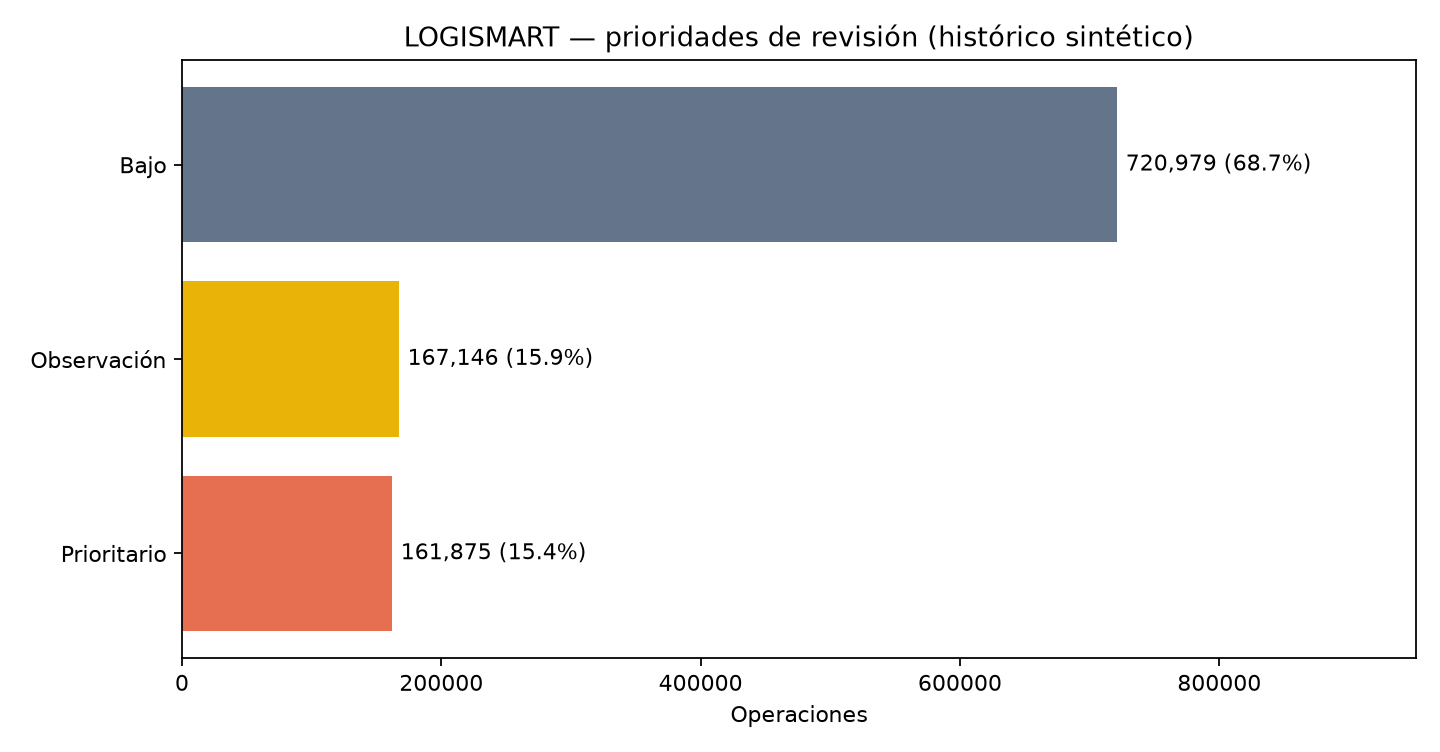

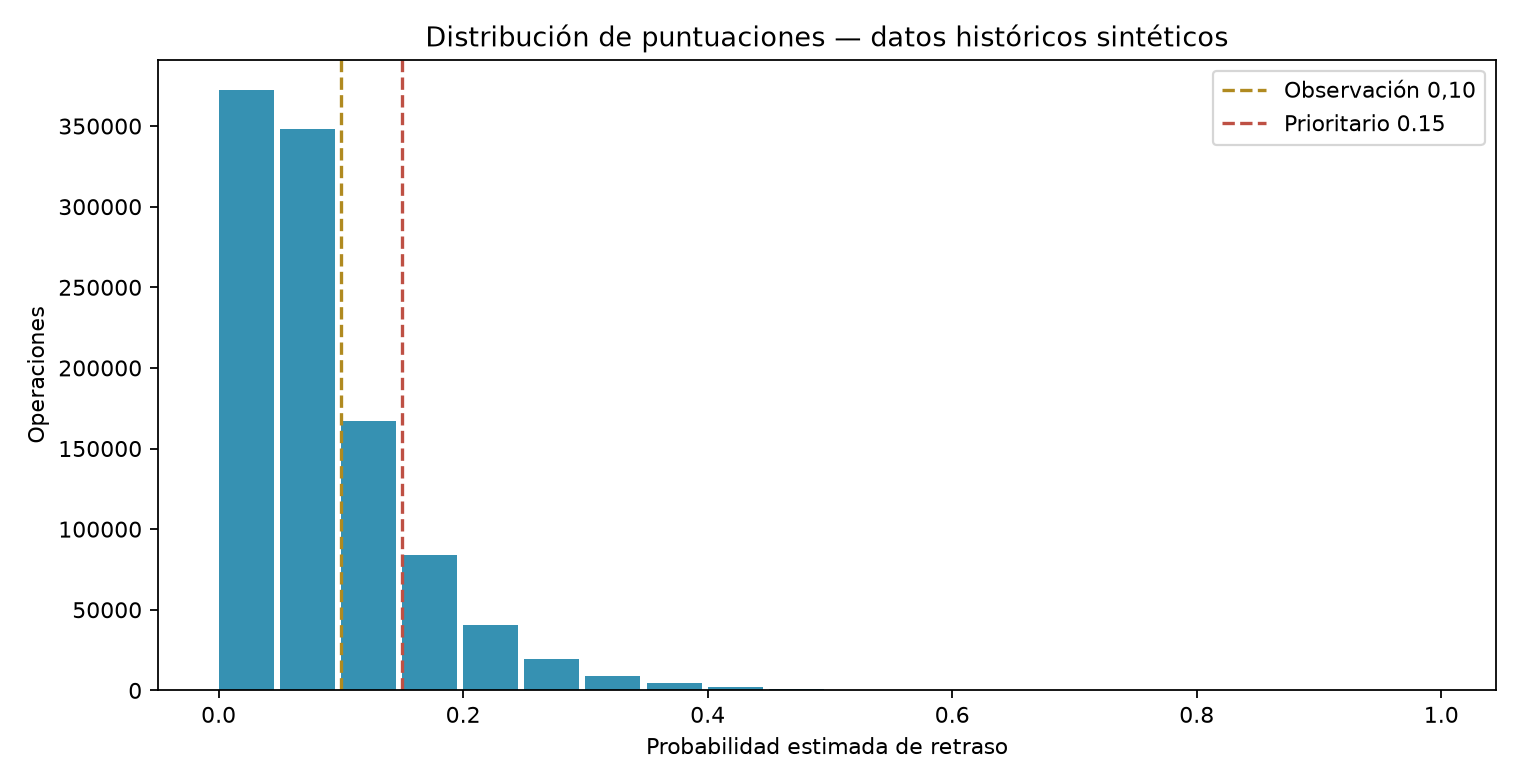

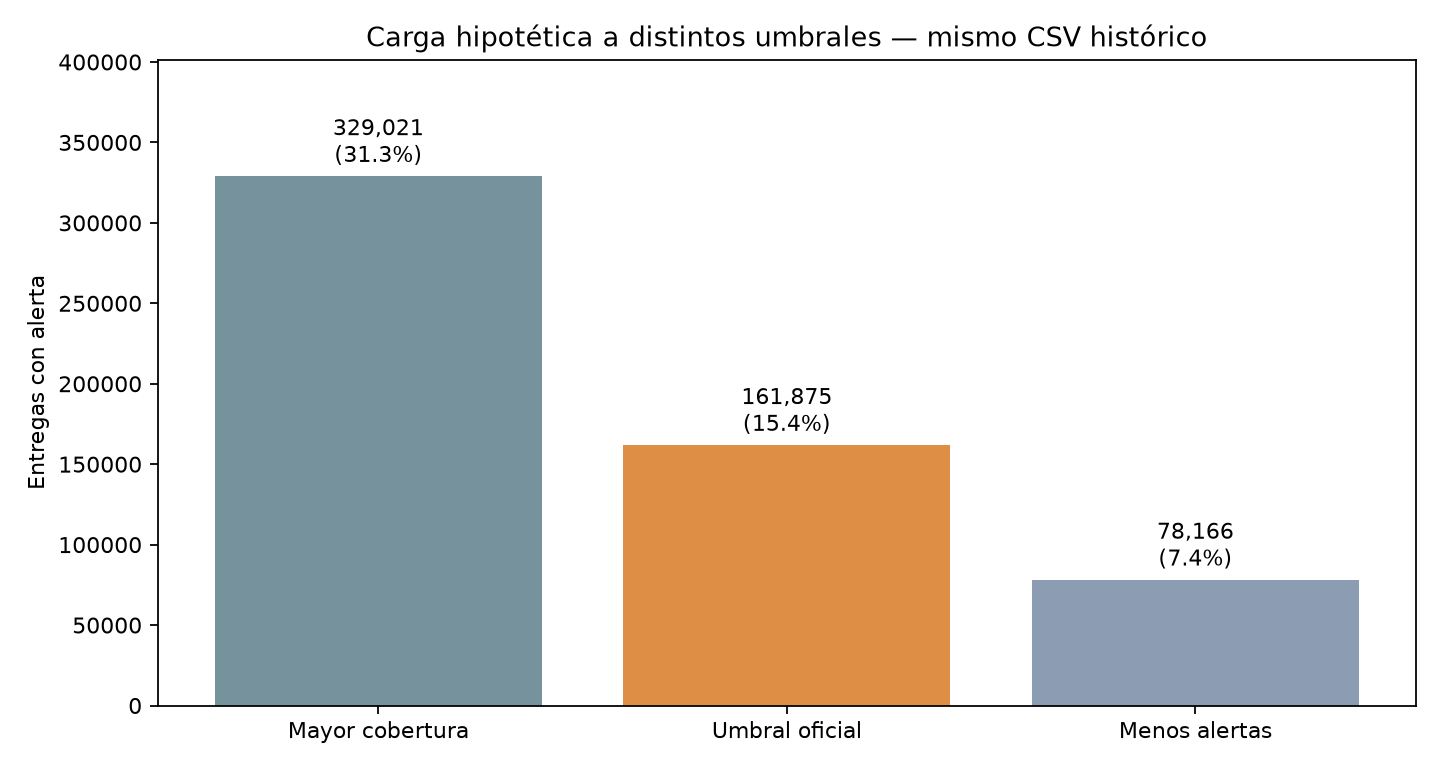

Panel HTML autónomo: output/visualizacion/panel_h6_t2.html


In [65]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, HTML

raiz_h6t2 = Path.cwd()
if raiz_h6t2.name == "notebooks":
    raiz_h6t2 = raiz_h6t2.parent
resumen_h6t2 = raiz_h6t2 / "output/resultados/visualizacion/h6_t2_indicadores.json"
if not resumen_h6t2.is_file():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso visualizar")
datos_h6t2 = json.loads(resumen_h6t2.read_text(encoding="utf-8"))
print("Corrida H6-T1:", datos_h6t2["corrida_h6_t1"])
print("Indicadores H6-T2:", datos_h6t2["indicadores"])
display(pd.read_csv(raiz_h6t2 / "output/resultados/visualizacion/h6_t2_niveles_riesgo.csv"))
display(pd.read_csv(raiz_h6t2 / "output/resultados/visualizacion/h6_t2_escenarios_umbrales.csv"))
for nombre in ("h6_t2_niveles_riesgo.png", "h6_t2_probabilidades.png", "h6_t2_escenarios_umbrales.png"):
    display(Image(filename=str(raiz_h6t2 / "output/graficos/visualizacion" / nombre)))
print("Panel HTML autónomo: output/visualizacion/panel_h6_t2.html")

### Interpretación de resultados y alcance — H6-T2

**Ejecución reproducida y comprobada.** Sobre **1.050.000 operaciones sintéticas** de la corrida H6-T1 `20261104T170000050763Z_a51e87`, se contabilizaron **161.875 alertas** utilizando el umbral oficial **0,15**, equivalentes a una **tasa de alertas de 15,42 %**. El código comprueba consistencia de conteos, secuencia de filas, clasificación y huella SHA-256 del CSV. No reentrena el XGBoost ni altera su umbral.

**Escenarios descriptivos sobre el mismo histórico:** con umbral 0,10 resultarían **329.021 alertas**; con 0,20, **78.166**. Estos escenarios sirven para visualizar el compromiso entre cobertura potencial y carga de revisión, pero **no estiman Precision, Recall ni atrasos evitados**: el archivo de predicciones no incluye el resultado real. Tampoco permiten afirmar qué umbral es operacionalmente viable sin conocer la capacidad de atención del equipo.

**Limitaciones y decisión abierta.** Los datos incluyen períodos usados para entrenar el modelo, por lo que esta visualización no constituye evaluación independiente. La clasificación de riesgo es relativa y requiere revisión humana. El formato final del dashboard/visualización sigue pendiente de confirmación con la docente; el panel HTML se presenta únicamente como un prototipo local y una evidencia visual, reutilizable en otras herramientas mediante archivos CSV y JSON.